# **Rain-Guard Agent: Project**

Yasir Rauf

Faculty of Arts and Sciences (FAS), Aga Khan University (AKU), Karachi, Pakistan

**Student ID:** 593752

**Assigned Station:** MURREE, NARAN, PLANDRI

**Random seed:** 3752

**Training Period:** 1971–2004

**Testing Period:** 2005–2012

Following the five-layer K-WaterGuard structure from the workshop (configure, perceive, reason, act, orchestrate), this project develops Rain-Guard, a daily rainfall-risk agent for MURREE, NARAN, and PLANDRI using random seed 3752 and a 1971–2004 training / 2005–2012 testing split. It applies data cleaning and quality control, forecasts next-day rainfall using individual and pooled Random Forest models, and examines annual precipitation trends using the Mann-Kendall test and Sen's slope. Based on data-driven thresholds, the agent assigns rainfall alert tiers with corresponding actions. The system runs through a single command to generate a status file and chart, supported by automated tests, an alert performance scorecard, and a human-approval safeguard.

In [ ]:
# Import libraries for data handling
import pandas as pd
import numpy as np

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for machine learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

# Import libraries for statistical analysis
from scipy.stats import kendalltau, theilslopes

# Import libraries for file handling
import os
import json
import warnings

# Set random seed
RANDOM_STATE = 3752
np.random.seed(RANDOM_STATE)

# Suppress unnecessary warnings
warnings.filterwarnings("ignore")

# Display confirmation
print("All libraries imported successfully.")
print("Random seed:", RANDOM_STATE)

All libraries imported successfully.
Random seed: 3752


In [ ]:
# Import Google Colab file upload utility
from google.colab import files

# Upload the rainfall dataset
uploaded = files.upload()

# Display uploaded file names
print("Uploaded files:", list(uploaded.keys()))

Saving Data_Input.xlsx to Data_Input (1).xlsx
Uploaded files: ['Data_Input (1).xlsx']


In [ ]:
# Load the Excel dataset
df = pd.read_excel("Data_Input.xlsx")

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display dataset dimensions
print("\nDataset dimensions:", df.shape)

# Display column names
print("\nDataset columns:")
print(df.columns.tolist())

First five rows of the dataset:


,Date,Station,Precipitation,Max,Min,Raintomorrow
0,1971-01-01,ASTORE,0.0,41.0,17.0,0
1,1971-01-02,ASTORE,0.0,39.0,18.0,0
2,1971-01-03,ASTORE,0.0,39.0,21.0,0
3,1971-01-04,ASTORE,0.0,41.0,NaN,0
4,1971-01-05,ASTORE,0.0,41.0,18.0,0



Dataset dimensions: (184092, 6)

Dataset columns:
['Date', 'Station', 'Precipitation', 'Max', 'Min', 'Raintomorrow']


In [ ]:
# Display dataset information
print("Dataset information:")
df.info()

# Display summary statistics
print("\nSummary statistics:")
display(df.describe())

# Count missing values in each column
print("\nMissing values in each column:")
display(df.isnull().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184092 entries, 0 to 184091
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           184092 non-null  datetime64[ns]
 1   Station        184092 non-null  object        
 2   Precipitation  174726 non-null  float64       
 3   Max            174844 non-null  float64       
 4   Min            174891 non-null  float64       
 5   Raintomorrow   184092 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(1), object(1)
memory usage: 8.4+ MB

Summary statistics:


,Date,Precipitation,Max,Min,Raintomorrow
count,184092,174726.000000,174844.000000,174891.000000,184092.000000
mean,1992-01-01 00:00:00,3.228808,24.218339,11.441303,0.280724
min,1971-01-01 00:00:00,-3.399516,-99.900000,-17.700000,0.000000
25%,1981-07-02 00:00:00,0.000000,17.700000,4.000000,0.000000
50%,1992-01-01 00:00:00,0.000000,24.400000,11.100000,0.000000
75%,2002-07-02 00:00:00,0.500000,31.700000,18.000000,1.000000
max,2012-12-31 00:00:00,291.800000,100.000000,100.000000,1.000000
std,NaN,10.246293,11.670645,10.191362,0.449354



Missing values in each column:


,0
Date,0
Station,0
Precipitation,9366
Max,9248
Min,9201
Raintomorrow,0


In [ ]:
# Define the three selected stations
selected_stations = ["MURREE", "NARAN", "PLANDRI"]

# Filter the original dataset for the selected stations
df_selected = df[df["Station"].isin(selected_stations)].copy()

# Display the number of observations for each station
print("Observations per station:")
display(df_selected["Station"].value_counts())

# Display the date range
print("\nDate range:")
print("Start date:", df_selected["Date"].min())
print("End date:", df_selected["Date"].max())

# Display the dimensions of the selected dataset
print("\nSelected dataset dimensions:", df_selected.shape)

Observations per station:


,count
Station,
MURREE,15341
PLANDRI,15341
NARAN,15341



Date range:
Start date: 1971-01-01 00:00:00
End date: 2012-12-31 00:00:00

Selected dataset dimensions: (46023, 6)


In [ ]:
# Count missing values for each variable by station
missing_by_station = df_selected.groupby("Station")[
    ["Precipitation", "Max", "Min"]
].apply(lambda x: x.isnull().sum())

# Display missing values by station
print("Missing values by station:")
display(missing_by_station)

Missing values by station:


,Precipitation,Max,Min
Station,,,
MURREE,762,771,809
NARAN,747,764,759
PLANDRI,771,751,794


In [ ]:
# Identify unusually low and high weather measurements
for station in selected_stations:
    station_data = df_selected[df_selected["Station"] == station]

    print("\nStation:", station)

    print("Minimum precipitation:",
          station_data["Precipitation"].min())

    print("Maximum precipitation:",
          station_data["Precipitation"].max())

    print("Minimum maximum-temperature value:",
          station_data["Max"].min())

    print("Maximum maximum-temperature value:",
          station_data["Max"].max())

    print("Minimum minimum-temperature value:",
          station_data["Min"].min())

    print("Maximum minimum-temperature value:",
          station_data["Min"].max())


Station: MURREE
Minimum precipitation: 0.0
Maximum precipitation: 255.0
Minimum maximum-temperature value: -2.6
Maximum maximum-temperature value: 100.0
Minimum minimum-temperature value: -10.5
Maximum minimum-temperature value: 100.0

Station: NARAN
Minimum precipitation: 0.0
Maximum precipitation: 127.0
Minimum maximum-temperature value: -13.9
Maximum maximum-temperature value: 37.8
Minimum minimum-temperature value: -15.6
Maximum minimum-temperature value: 33.7

Station: PLANDRI
Minimum precipitation: 0.0
Maximum precipitation: 233.4
Minimum maximum-temperature value: 1.1
Maximum maximum-temperature value: 41.7
Minimum minimum-temperature value: -15.6
Maximum minimum-temperature value: 27.8


In [ ]:
# Count potential placeholder temperature values by station
for station in selected_stations:

    station_data = df_selected[df_selected["Station"] == station]

    print("\nStation:", station)

    print("Max temperature values equal to 100:",
          (station_data["Max"] == 100).sum())

    print("Min temperature values equal to 100:",
          (station_data["Min"] == 100).sum())

    print("Max temperature values equal to -99.9:",
          (station_data["Max"] == -99.9).sum())

    print("Min temperature values equal to -99.9:",
          (station_data["Min"] == -99.9).sum())


Station: MURREE
Max temperature values equal to 100: 1
Min temperature values equal to 100: 1
Max temperature values equal to -99.9: 0
Min temperature values equal to -99.9: 0

Station: NARAN
Max temperature values equal to 100: 0
Min temperature values equal to 100: 0
Max temperature values equal to -99.9: 0
Min temperature values equal to -99.9: 0

Station: PLANDRI
Max temperature values equal to 100: 0
Min temperature values equal to 100: 0
Max temperature values equal to -99.9: 0
Min temperature values equal to -99.9: 0


In [ ]:
# Examine the distribution of Rain tomorrow labels
for station in selected_stations:

    station_data = df_selected[df_selected["Station"] == station]

    print("\nStation:", station)

    # Count rainy and non-rainy days
    display(station_data["Raintomorrow"].value_counts().sort_index())

    # Calculate percentage of each class
    display(
        station_data["Raintomorrow"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
    )


Station: MURREE


,count
Raintomorrow,
0,10246
1,5095


,proportion
Raintomorrow,
0,66.788345
1,33.211655



Station: NARAN


,count
Raintomorrow,
0,10150
1,5191


,proportion
Raintomorrow,
0,66.162571
1,33.837429



Station: PLANDRI


,count
Raintomorrow,
0,11555
1,3786


,proportion
Raintomorrow,
0,75.321035
1,24.678965


In [ ]:
# Check the number of observations in each year by station
df_selected["Year"] = df_selected["Date"].dt.year

yearly_counts = df_selected.groupby(
    ["Station", "Year"]
).size().reset_index(name="Observations")

# Display the first and last years for each station
for station in selected_stations:

    station_years = yearly_counts[
        yearly_counts["Station"] == station
    ]

    print("\nStation:", station)

    print("First five years:")
    display(station_years.head())

    print("Last five years:")
    display(station_years.tail())


Station: MURREE
First five years:


,Station,Year,Observations
0,MURREE,1971,365
1,MURREE,1972,366
2,MURREE,1973,365
3,MURREE,1974,365
4,MURREE,1975,365


Last five years:


,Station,Year,Observations
37,MURREE,2008,366
38,MURREE,2009,365
39,MURREE,2010,365
40,MURREE,2011,365
41,MURREE,2012,366



Station: NARAN
First five years:


,Station,Year,Observations
42,NARAN,1971,365
43,NARAN,1972,366
44,NARAN,1973,365
45,NARAN,1974,365
46,NARAN,1975,365


... (2 outputs left out)


Station: PLANDRI
First five years:


,Station,Year,Observations
84,PLANDRI,1971,365
85,PLANDRI,1972,366
86,PLANDRI,1973,365
87,PLANDRI,1974,365
88,PLANDRI,1975,365


Last five years:


,Station,Year,Observations
121,PLANDRI,2008,366
122,PLANDRI,2009,365
123,PLANDRI,2010,365
124,PLANDRI,2011,365
125,PLANDRI,2012,366


In [ ]:
# Separate observations into training and testing periods
train_data = df_selected[
    (df_selected["Date"].dt.year >= 1971) &
    (df_selected["Date"].dt.year <= 2004)
].copy()

test_data = df_selected[
    (df_selected["Date"].dt.year >= 2005) &
    (df_selected["Date"].dt.year <= 2012)
].copy()

# Display observation counts by station
print("Training observations:")
display(train_data["Station"].value_counts())

print("\nTesting observations:")
display(test_data["Station"].value_counts())

# Display date ranges
print("\nTraining period:",
      train_data["Date"].min(), "to", train_data["Date"].max())

print("Testing period:",
      test_data["Date"].min(), "to", test_data["Date"].max())

Training observations:


,count
Station,
MURREE,12419
PLANDRI,12419
NARAN,12419



Testing observations:


,count
Station,
MURREE,2922
PLANDRI,2922
NARAN,2922



Training period: 1971-01-01 00:00:00 to 2004-12-31 00:00:00
Testing period: 2005-01-01 00:00:00 to 2012-12-31 00:00:00


In [ ]:
%%writefile config.py

# Rain-Guard Agent Configuration

# Selected weather stations
STATIONS = ["MURREE", "NARAN", "PLANDRI"]

# Random seed for reproducibility
RANDOM_STATE = 3752

# Training and testing periods
TRAIN_START_YEAR = 1971
TRAIN_END_YEAR = 2004

TEST_START_YEAR = 2005
TEST_END_YEAR = 2012

# Data quality control settings

# Values treated as temperature placeholders
TEMPERATURE_PLACEHOLDERS = [100, -99.9]

# Robust outlier detection threshold using MAD
MAD_THRESHOLD = 3.5

# Minimum physically valid precipitation
MIN_PRECIPITATION = 0

# Rainfall prediction label
TARGET_COLUMN = "Raintomorrow"

# Weather variables
WEATHER_COLUMNS = ["Precipitation", "Max", "Min"]

print("Rain-Guard configuration created successfully.")

Writing config.py


In [ ]:
# Verify that the configuration file exists
print("Configuration file exists:", os.path.exists("config.py"))

Configuration file exists: True


In [ ]:
# Import project configuration
import config

# Display selected configuration settings
print("Selected stations:", config.STATIONS)
print("Random seed:", config.RANDOM_STATE)
print("MAD threshold:", config.MAD_THRESHOLD)

Rain-Guard configuration created successfully.
Selected stations: ['MURREE', 'NARAN', 'PLANDRI']
Random seed: 3752
MAD threshold: 3.5


In [ ]:
%%writefile collector.py

# Import required libraries
import pandas as pd
import numpy as np

# Import project configuration
import config


def load_data(file_path="Data_Input.xlsx"):

    # Load the original Excel dataset
    df = pd.read_excel(file_path)

    # Convert dates into datetime format
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    # Select the three assigned stations
    df = df[df["Station"].isin(config.STATIONS)].copy()

    # Sort observations by station and date
    df = df.sort_values(["Station", "Date"]).reset_index(drop=True)

    # Return selected dataset
    return df

Writing collector.py


In [ ]:
# Import the data-loading function
from collector import load_data

# Load the selected station data
raw_data = load_data()

# Display the number of observations
print("Loaded observations:", len(raw_data))

# Display station counts
print("\nObservations per station:")
display(raw_data["Station"].value_counts())

# Display the first five observations
print("\nFirst five observations:")
display(raw_data.head())

Loaded observations: 46023

Observations per station:


,count
Station,
MURREE,15341
NARAN,15341
PLANDRI,15341



First five observations:


,Date,Station,Precipitation,Max,Min,Raintomorrow
0,1971-01-01,MURREE,0.0,15.039623,11.420360,0
1,1971-01-02,MURREE,0.0,14.136571,12.861415,0
2,1971-01-03,MURREE,0.0,14.054616,13.345803,0
3,1971-01-04,MURREE,0.0,12.296908,NaN,0
4,1971-01-05,MURREE,0.0,14.295338,12.662025,0


In [ ]:
%%writefile -a collector.py


def basic_quality_control(df):

    # Create a copy to preserve the original dataset
    df = df.copy()

    # Create a log to record data-quality changes
    qc_log = []

    # Replace configured temperature placeholders
    for column in ["Max", "Min"]:

        placeholder_count = df[column].isin(
            config.TEMPERATURE_PLACEHOLDERS
        ).sum()

        df.loc[
            df[column].isin(config.TEMPERATURE_PLACEHOLDERS),
            column
        ] = np.nan

        qc_log.append({
            "Variable": column,
            "Change": "Temperature placeholders replaced",
            "Values affected": int(placeholder_count)
        })

    # Replace negative precipitation values
    negative_precipitation = (df["Precipitation"] < config.MIN_PRECIPITATION).sum()

    df.loc[
        df["Precipitation"] < config.MIN_PRECIPITATION,
        "Precipitation"
    ] = np.nan

    qc_log.append({
        "Variable": "Precipitation",
        "Change": "Negative values replaced",
        "Values affected": int(negative_precipitation)
    })

    # Convert the quality-control log into a DataFrame
    qc_log = pd.DataFrame(qc_log)

    # Return cleaned data and quality-control log
    return df, qc_log

Appending to collector.py


In [ ]:
# Apply basic quality control
cleaned_data, qc_log = basic_quality_control(raw_data)

# Display the quality-control log
print("Quality-control changes:")
display(qc_log)

# Display remaining missing values
print("\nMissing values after basic quality control:")
display(cleaned_data[["Precipitation", "Max", "Min"]].isnull().sum())

Quality-control changes:


,Variable,Change,Values affected
0,Max,Temperature placeholders replaced,1
1,Min,Temperature placeholders replaced,1
2,Precipitation,Negative values replaced,0



Missing values after basic quality control:


,0
Precipitation,2280
Max,2287
Min,2363


In [ ]:
%%writefile -a collector.py

def detect_outliers(df):

    # Create a copy of the dataset
    df = df.copy()

    # Create a log for detected outliers
    outlier_log = []

    # Examine each station separately
    for station in config.STATIONS:

        station_index = df["Station"] == station

        # Examine each weather variable
        for column in config.WEATHER_COLUMNS:

            values = df.loc[station_index, column].dropna()

            # Calculate the median
            median_value = values.median()

            # Calculate the median absolute deviation
            mad_value = np.median(np.abs(values - median_value))

            # Avoid division by zero
            if mad_value == 0:
                outlier_count = 0

            else:
                # Calculate robust modified Z-scores
                modified_z = 0.6745 * (
                    values - median_value
                ) / mad_value

                # Count observations exceeding the configured threshold
                outlier_count = (
                    modified_z.abs() > config.MAD_THRESHOLD
                ).sum()

            # Record the results
            outlier_log.append({
                "Station": station,
                "Variable": column,
                "Median": median_value,
                "MAD": mad_value,
                "Outliers detected": int(outlier_count)
            })

    # Convert the log into a DataFrame
    outlier_log = pd.DataFrame(outlier_log)

    # Return original observations and outlier report
    return df, outlier_log

Appending to collector.py


In [ ]:
# Reload the collector module
import importlib
import collector

importlib.reload(collector)

# Import the outlier detection function
from collector import detect_outliers

# Detect unusual observations
checked_data, outlier_log = detect_outliers(cleaned_data)

# Display the outlier detection results
print("MAD-based outlier detection results:")
display(outlier_log)

MAD-based outlier detection results:


,Station,Variable,Median,MAD,Outliers detected
0,MURREE,Precipitation,0.0,0.0,0
1,MURREE,Max,20.0,5.0,1356
2,MURREE,Min,11.3,5.7,749
3,NARAN,Precipitation,0.0,0.0,0
4,NARAN,Max,13.3,8.9,0
5,NARAN,Min,10.6,7.2,0
6,PLANDRI,Precipitation,0.0,0.0,0
7,PLANDRI,Max,24.4,5.0,0
8,PLANDRI,Min,9.4,6.2,0


In [ ]:
%%writefile -a collector.py


def detect_monthly_outliers(df):

    # Create a copy of the dataset
    df = df.copy()

    # Extract calendar month
    df["Month"] = df["Date"].dt.month

    # Create an outlier report
    outlier_log = []

    # Examine each station
    for station in config.STATIONS:

        station_data = df[df["Station"] == station]

        # Examine each weather variable
        for column in config.WEATHER_COLUMNS:

            # Examine each calendar month separately
            for month in range(1, 13):

                values = station_data.loc[
                    station_data["Month"] == month, column
                ].dropna()

                # For precipitation, examine non-zero rainfall only
                if column == "Precipitation":
                    values = values[values > 0]

                # Calculate median and MAD
                if len(values) < 10:
                    continue

                median_value = values.median()
                mad_value = np.median(
                    np.abs(values - median_value)
                )

                # Detect outliers when MAD is non-zero
                if mad_value == 0:
                    outlier_count = 0
                else:
                    modified_z = (
                        0.6745 * (values - median_value) / mad_value
                    )

                    outlier_count = (
                        modified_z.abs() > config.MAD_THRESHOLD
                    ).sum()

                # Record monthly results
                outlier_log.append({
                    "Station": station,
                    "Variable": column,
                    "Month": month,
                    "Observations": len(values),
                    "Median": median_value,
                    "MAD": mad_value,
                    "Outliers detected": int(outlier_count)
                })

    # Convert results into a DataFrame
    outlier_log = pd.DataFrame(outlier_log)

    # Return data and outlier report
    return df.drop(columns=["Month"]), outlier_log

Appending to collector.py


In [ ]:
# Reload the collector module
import importlib
import collector

importlib.reload(collector)

# Import the revised function
from collector import detect_monthly_outliers

# Run monthly outlier detection
checked_data, monthly_outlier_log = detect_monthly_outliers(cleaned_data)

# Display monthly outlier results
print("Monthly MAD-based outlier detection:")
display(monthly_outlier_log)

# Calculate total flagged observations by station and variable
print("\nTotal flagged observations:")
display(
    monthly_outlier_log.groupby(
        ["Station", "Variable"]
    )["Outliers detected"].sum().reset_index()
)

Monthly MAD-based outlier detection:


,Station,Variable,Month,Observations,Median,MAD,Outliers detected
0,MURREE,Precipitation,1,324,7.550000,6.550000,33
1,MURREE,Precipitation,2,376,8.250000,7.250000,38
2,MURREE,Precipitation,3,456,7.700000,6.700000,29
3,MURREE,Precipitation,4,419,5.800000,4.843403,38
4,MURREE,Precipitation,5,401,4.500000,3.543403,29
...,...,...,...,...,...,...,...
103,PLANDRI,Min,8,1236,17.800000,1.600000,28
104,PLANDRI,Min,9,1211,15.000000,1.700000,31
105,PLANDRI,Min,10,1230,9.400000,2.300000,0
106,PLANDRI,Min,11,1186,4.441791,2.441791,0



Total flagged observations:


,Station,Variable,Outliers detected
0,MURREE,Max,1587
1,MURREE,Min,1496
2,MURREE,Precipitation,424
3,NARAN,Max,56
4,NARAN,Min,815
5,NARAN,Precipitation,117
6,PLANDRI,Max,71
7,PLANDRI,Min,123
8,PLANDRI,Precipitation,316


In [ ]:
%%writefile -a collector.py


def split_data(df):

    # Separate training observations
    train_data = df[
        (df["Date"].dt.year >= config.TRAIN_START_YEAR) &
        (df["Date"].dt.year <= config.TRAIN_END_YEAR)
    ].copy()

    # Separate testing observations
    test_data = df[
        (df["Date"].dt.year >= config.TEST_START_YEAR) &
        (df["Date"].dt.year <= config.TEST_END_YEAR)
    ].copy()

    # Return both datasets
    return train_data, test_data

Appending to collector.py


In [ ]:
# Reload the collector module
import importlib
import collector

importlib.reload(collector)

# Import the splitting function
from collector import split_data

# Split the cleaned dataset chronologically
train_data, test_data = split_data(checked_data)

# Display observations per station
print("Training observations:")
display(train_data["Station"].value_counts())

print("\nTesting observations:")
display(test_data["Station"].value_counts())

# Display date ranges
print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

# Confirm that the periods do not overlap
print("\nTraining and testing periods overlap:",
      train_data["Date"].max() >= test_data["Date"].min())

Training observations:


,count
Station,
MURREE,12419
NARAN,12419
PLANDRI,12419



Testing observations:


,count
Station,
MURREE,2922
NARAN,2922
PLANDRI,2922



Training period:
1971-01-01 00:00:00 to 2004-12-31 00:00:00

Testing period:
2005-01-01 00:00:00 to 2012-12-31 00:00:00

Training and testing periods overlap: False


In [ ]:
%%writefile -a collector.py


def impute_missing_values(train_data, test_data):

    # Create copies of both datasets
    train_data = train_data.copy()
    test_data = test_data.copy()

    # Create an imputation log
    imputation_log = []

    # Calculate medians using training data only
    for station in config.STATIONS:

        station_train = train_data["Station"] == station
        station_test = test_data["Station"] == station

        for column in config.WEATHER_COLUMNS:

            # Calculate the station-specific training median
            median_value = train_data.loc[
                station_train, column
            ].median()

            # Use the overall training median as a fallback
            if pd.isna(median_value):
                median_value = train_data[column].median()

            # Count missing values before imputation
            train_missing = train_data.loc[
                station_train, column
            ].isna().sum()

            test_missing = test_data.loc[
                station_test, column
            ].isna().sum()

            # Fill missing values using the training median
            train_data.loc[
                station_train, column
            ] = train_data.loc[
                station_train, column
            ].fillna(median_value)

            test_data.loc[
                station_test, column
            ] = test_data.loc[
                station_test, column
            ].fillna(median_value)

            # Record imputation details
            imputation_log.append({
                "Station": station,
                "Variable": column,
                "Training values imputed": int(train_missing),
                "Testing values imputed": int(test_missing),
                "Training median used": round(float(median_value), 3)
            })

    # Return imputed datasets and log
    return train_data, test_data, pd.DataFrame(imputation_log)

Appending to collector.py


In [ ]:
# Reload the collector module
import importlib
import collector

importlib.reload(collector)

# Import the imputation function
from collector import impute_missing_values

# Impute missing weather observations
train_imputed, test_imputed, imputation_log = impute_missing_values(
    train_data, test_data
)

# Display the imputation log
print("Missing-value imputation report:")
display(imputation_log)

# Check remaining missing weather values
print("\nMissing values in training data:")
display(train_imputed[config.WEATHER_COLUMNS].isnull().sum())

print("\nMissing values in testing data:")
display(test_imputed[config.WEATHER_COLUMNS].isnull().sum())

Missing-value imputation report:


,Station,Variable,Training values imputed,Testing values imputed,Training median used
0,MURREE,Precipitation,605,157,0.0
1,MURREE,Max,633,139,20.0
2,MURREE,Min,645,165,11.7
3,NARAN,Precipitation,610,137,0.0
4,NARAN,Max,615,149,13.3
5,NARAN,Min,618,141,11.0
6,PLANDRI,Precipitation,629,142,0.0
7,PLANDRI,Max,614,137,24.0
8,PLANDRI,Min,640,154,9.0



Missing values in training data:


,0
Precipitation,0
Max,0
Min,0



Missing values in testing data:


,0
Precipitation,0
Max,0
Min,0


In [ ]:
# Display final dataset dimensions
print("Training dataset dimensions:", train_imputed.shape)
print("Testing dataset dimensions:", test_imputed.shape)

# Check target label distribution in training data
print("\nTraining target distribution:")
display(train_imputed["Raintomorrow"].value_counts().sort_index())

# Check target label distribution in testing data
print("\nTesting target distribution:")
display(test_imputed["Raintomorrow"].value_counts().sort_index())

# Confirm target labels contain only binary values
print("\nTraining labels are binary:",
      train_imputed["Raintomorrow"].isin([0, 1]).all())

print("Testing labels are binary:",
      test_imputed["Raintomorrow"].isin([0, 1]).all())

Training dataset dimensions: (37257, 6)
Testing dataset dimensions: (8766, 6)

Training target distribution:


,count
Raintomorrow,
0,25387
1,11870



Testing target distribution:


,count
Raintomorrow,
0,6564
1,2202



Training labels are binary: True
Testing labels are binary: True


In [ ]:
%%writefile features.py

# Import required libraries
import numpy as np
import pandas as pd

# Import project configuration
import config


def create_features(df):

    # Create a copy of the dataset
    df = df.copy()

    # Extract day of year
    day_of_year = df["Date"].dt.dayofyear

    # Create cyclical seasonal features
    df["Season_Sin"] = np.sin(
        2 * np.pi * day_of_year / 365.25
    )

    df["Season_Cos"] = np.cos(
        2 * np.pi * day_of_year / 365.25
    )

    # Define predictor variables
    feature_columns = [
        "Precipitation",
        "Max",
        "Min",
        "Season_Sin",
        "Season_Cos"
    ]

    # Extract model features
    X = df[feature_columns].copy()

    # Extract next-day rainfall labels
    y = df[config.TARGET_COLUMN].copy()

    # Return predictors and target
    return X, y

Writing features.py


In [ ]:
# Import the feature-engineering function
from features import create_features

# Generate training features and labels
X_train, y_train = create_features(train_imputed)

# Generate testing features and labels
X_test, y_test = create_features(test_imputed)

# Display feature columns
print("Predictor variables:")
print(X_train.columns.tolist())

# Display dataset dimensions
print("\nTraining features:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nTesting features:", X_test.shape)
print("Testing labels:", y_test.shape)

# Check for target leakage
print("\nRaintomorrow included in predictors:",
      "Raintomorrow" in X_train.columns)

# Display first five feature observations
print("\nFirst five training observations:")
display(X_train.head())

Predictor variables:
['Precipitation', 'Max', 'Min', 'Season_Sin', 'Season_Cos']

Training features: (37257, 5)
Training labels: (37257,)

Testing features: (8766, 5)
Testing labels: (8766,)

Raintomorrow included in predictors: False

First five training observations:


,Precipitation,Max,Min,Season_Sin,Season_Cos
0,0.0,15.039623,11.420360,0.017202,0.999852
1,0.0,14.136571,12.861415,0.034398,0.999408
2,0.0,14.054616,13.345803,0.051584,0.998669
3,0.0,12.296908,11.700000,0.068755,0.997634
4,0.0,14.295338,12.662025,0.085906,0.996303


In [ ]:
%%writefile models.py

# Import required libraries
from sklearn.ensemble import RandomForestClassifier

# Import project configuration
import config

# Import feature engineering
from features import create_features


def train_random_forest_models(train_data):

    # Store trained models
    models = {}

    # Train one model for each station
    for station in config.STATIONS:

        # Select station-specific training data
        station_data = train_data[
            train_data["Station"] == station
        ].copy()

        # Generate predictors and target labels
        X, y = create_features(station_data)

        # Initialize Random Forest classifier
        model = RandomForestClassifier(
            n_estimators=100,
            random_state=config.RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1
        )

        # Train the model
        model.fit(X, y)

        # Store the trained model
        models[station] = model

    # Generate pooled training features
    X_pooled, y_pooled = create_features(train_data)

    # Initialize pooled Random Forest classifier
    pooled_model = RandomForestClassifier(
        n_estimators=100,
        random_state=config.RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    )

    # Train pooled model using all three stations
    pooled_model.fit(X_pooled, y_pooled)

    # Store pooled model
    models["POOLED"] = pooled_model

    # Return all trained models
    return models

Writing models.py


In [ ]:
# Import the model-training function
from models import train_random_forest_models

# Train all four Random Forest models
trained_models = train_random_forest_models(train_imputed)

# Display trained model names
print("Random Forest models trained successfully:")

for model_name in trained_models:
    print("-", model_name)

# Confirm the number of trained models
print("\nTotal models:", len(trained_models))

Random Forest models trained successfully:
- MURREE
- NARAN
- PLANDRI
- POOLED

Total models: 4


In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store evaluation results
evaluation_results = []

# Evaluate each station-specific model
for station in config.STATIONS:

    # Select station testing data
    station_test = test_imputed[
        test_imputed["Station"] == station
    ].copy()

    # Generate testing features and labels
    X_test_station, y_test_station = create_features(station_test)

    # Generate predictions
    predictions = trained_models[station].predict(X_test_station)

    # Calculate evaluation metrics
    evaluation_results.append({
        "Model": station,
        "Accuracy": accuracy_score(y_test_station, predictions),
        "Precision": precision_score(y_test_station, predictions, zero_division=0),
        "Recall": recall_score(y_test_station, predictions, zero_division=0),
        "F1-score": f1_score(y_test_station, predictions, zero_division=0)
    })

# Evaluate the pooled model on all testing stations
X_test_pooled, y_test_pooled = create_features(test_imputed)

pooled_predictions = trained_models["POOLED"].predict(X_test_pooled)

evaluation_results.append({
    "Model": "POOLED",
    "Accuracy": accuracy_score(y_test_pooled, pooled_predictions),
    "Precision": precision_score(y_test_pooled, pooled_predictions, zero_division=0),
    "Recall": recall_score(y_test_pooled, pooled_predictions, zero_division=0),
    "F1-score": f1_score(y_test_pooled, pooled_predictions, zero_division=0)
})

# Display evaluation results
evaluation_df = pd.DataFrame(evaluation_results)

print("Random Forest model evaluation:")
display(evaluation_df.round(3))

Random Forest model evaluation:


,Model,Accuracy,Precision,Recall,F1-score
0,MURREE,0.974,0.997,0.929,0.962
1,NARAN,0.975,0.942,0.956,0.949
2,PLANDRI,0.989,0.989,0.947,0.968
3,POOLED,0.980,0.981,0.941,0.960


In [ ]:
# Sort observations by station and date
alignment_data = raw_data.sort_values(
    ["Station", "Date"]
).copy()

# Obtain the following day's precipitation for each station
alignment_data["Next_Day_Precipitation"] = (
    alignment_data.groupby("Station")["Precipitation"].shift(-1)
)

# Identify records where next-day precipitation is available
valid_data = alignment_data.dropna(
    subset=["Next_Day_Precipitation"]
).copy()

# Convert next-day precipitation into a binary rainfall indicator
valid_data["Next_Day_Rain"] = (
    valid_data["Next_Day_Precipitation"] > 0
).astype(int)

# Calculate agreement with next-day rainfall
next_day_agreement = (
    valid_data["Raintomorrow"] ==
    valid_data["Next_Day_Rain"]
).mean()

# Calculate agreement with same-day rainfall
valid_data["Same_Day_Rain"] = (
    valid_data["Precipitation"] > 0
).astype(int)

same_day_agreement = (
    valid_data["Raintomorrow"] ==
    valid_data["Same_Day_Rain"]
).mean()

# Display results
print("Target-label alignment audit:")
print("Agreement with next-day rainfall:", round(next_day_agreement, 4))
print("Agreement with same-day rainfall:", round(same_day_agreement, 4))

Target-label alignment audit:
Agreement with next-day rainfall: 0.7644
Agreement with same-day rainfall: 0.9846


In [ ]:
# Display sample observations with current and next-day rainfall
print("Comparing existing labels with observed rainfall:")

display(
    valid_data[
        [
            "Date",
            "Station",
            "Precipitation",
            "Raintomorrow",
            "Next_Day_Precipitation",
            "Next_Day_Rain"
        ]
    ].head(20)
)

Comparing existing labels with observed rainfall:


,Date,Station,Precipitation,Raintomorrow,Next_Day_Precipitation,Next_Day_Rain
0,1971-01-01,MURREE,0.0,0,0.0,0
1,1971-01-02,MURREE,0.0,0,0.0,0
2,1971-01-03,MURREE,0.0,0,0.0,0
3,1971-01-04,MURREE,0.0,0,0.0,0
4,1971-01-05,MURREE,0.0,0,0.0,0
5,1971-01-06,MURREE,0.0,0,0.0,0
6,1971-01-07,MURREE,0.0,0,0.0,0
7,1971-01-08,MURREE,0.0,0,0.0,0
8,1971-01-09,MURREE,0.0,0,0.0,0
9,1971-01-10,MURREE,0.0,0,0.0,0


In [ ]:
%%writefile -a collector.py


def create_next_day_target(df):

    # Create a copy and sort observations chronologically
    df = df.copy()
    df = df.sort_values(["Station", "Date"]).reset_index(drop=True)

    # Obtain the following observation's date and precipitation
    df["Next_Date"] = df.groupby("Station")["Date"].shift(-1)

    df["Next_Day_Precipitation"] = (
        df.groupby("Station")["Precipitation"].shift(-1)
    )

    # Confirm that the following observation is exactly one day later
    consecutive_day = (
        df["Next_Date"] == df["Date"] + pd.Timedelta(days=1)
    )

    # Keep only observations with valid next-day precipitation
    valid_target = (
        consecutive_day &
        df["Next_Day_Precipitation"].notna()
    )

    df = df.loc[valid_target].copy()

    # Construct the next-day rainfall target
    df["Raintomorrow"] = (
        df["Next_Day_Precipitation"] > 0
    ).astype(int)

    # Remove temporary columns
    df = df.drop(
        columns=["Next_Date", "Next_Day_Precipitation"]
    )

    # Return corrected dataset
    return df

Appending to collector.py


In [ ]:
# Reload the collector module
import importlib
import collector

importlib.reload(collector)

# Import the corrected target function
from collector import create_next_day_target

# Start with the original selected observations
corrected_data = raw_data.copy()

# Apply basic quality control
corrected_data, corrected_qc_log = collector.basic_quality_control(
    corrected_data
)

# Construct the actual next-day rainfall target
corrected_data = create_next_day_target(corrected_data)

# Display dataset dimensions
print("Corrected dataset dimensions:", corrected_data.shape)

# Display corrected target distribution
print("\nCorrected next-day target distribution:")
display(corrected_data["Raintomorrow"].value_counts().sort_index())

# Display observations per station
print("\nObservations per station:")
display(corrected_data["Station"].value_counts())

# Confirm target labels are binary
print("\nTarget labels are binary:",
      corrected_data["Raintomorrow"].isin([0, 1]).all())

Corrected dataset dimensions: (43740, 6)

Corrected next-day target distribution:


,count
Raintomorrow,
0,30375
1,13365



Observations per station:


,count
Station,
NARAN,14593
MURREE,14578
PLANDRI,14569



Target labels are binary: True


In [ ]:
# Import the chronological splitting function
from collector import split_data

# Split the corrected dataset
train_data, test_data = split_data(corrected_data)

# Display training observations
print("Training observations:")
display(train_data["Station"].value_counts())

# Display testing observations
print("\nTesting observations:")
display(test_data["Station"].value_counts())

# Display date ranges
print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

# Confirm no overlap
print("\nTraining and testing overlap:",
      train_data["Date"].max() >= test_data["Date"].min())

Training observations:


,count
Station,
MURREE,11814
NARAN,11809
PLANDRI,11790



Testing observations:


,count
Station,
NARAN,2784
PLANDRI,2779
MURREE,2764



Training period:
1971-01-01 00:00:00 to 2004-12-31 00:00:00

Testing period:
2005-01-01 00:00:00 to 2012-12-30 00:00:00

Training and testing overlap: False


In [ ]:
%%writefile -a collector.py


def split_data_strict(df):

    # Define the first day of the testing period
    test_start = pd.Timestamp(
        year=config.TEST_START_YEAR,
        month=1,
        day=1
    )

    # Exclude the final training date to prevent boundary leakage
    train_data = df[
        (df["Date"].dt.year >= config.TRAIN_START_YEAR) &
        (df["Date"] < test_start - pd.Timedelta(days=1))
    ].copy()

    # Select testing observations
    test_data = df[
        (df["Date"].dt.year >= config.TEST_START_YEAR) &
        (df["Date"].dt.year <= config.TEST_END_YEAR)
    ].copy()

    # Return training and testing datasets
    return train_data, test_data

Appending to collector.py


In [ ]:
# Reload the collector module
import importlib
import collector

importlib.reload(collector)

# Import the corrected splitting function
from collector import split_data_strict

# Apply the corrected chronological split
train_data, test_data = split_data_strict(corrected_data)

# Display training observations
print("Training observations:")
display(train_data["Station"].value_counts())

# Display testing observations
print("\nTesting observations:")
display(test_data["Station"].value_counts())

# Display date ranges
print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

# Confirm that the training and testing periods do not overlap
print("\nTraining and testing overlap:",
      train_data["Date"].max() >= test_data["Date"].min())

Training observations:


,count
Station,
MURREE,11813
NARAN,11808
PLANDRI,11789



Testing observations:


,count
Station,
NARAN,2784
PLANDRI,2779
MURREE,2764



Training period:
1971-01-01 00:00:00 to 2004-12-30 00:00:00

Testing period:
2005-01-01 00:00:00 to 2012-12-30 00:00:00

Training and testing overlap: False


In [ ]:
# Import the missing-value imputation function
from collector import impute_missing_values

# Impute missing values using training-period medians
train_imputed, test_imputed, imputation_log = impute_missing_values(
    train_data,
    test_data
)

# Display the imputation log
print("Missing-value imputation report:")
display(imputation_log)

# Confirm that no missing weather values remain
print("\nMissing values in training data:")
display(train_imputed[["Precipitation", "Max", "Min"]].isnull().sum())

print("\nMissing values in testing data:")
display(test_imputed[["Precipitation", "Max", "Min"]].isnull().sum())

Missing-value imputation report:


,Station,Variable,Training values imputed,Testing values imputed,Training median used
0,MURREE,Precipitation,580,148,0.0
1,MURREE,Max,604,135,20.0
2,MURREE,Min,613,153,11.7
3,NARAN,Precipitation,580,127,0.0
4,NARAN,Max,590,140,13.3
5,NARAN,Min,592,134,11.0
6,PLANDRI,Precipitation,599,136,0.0
7,PLANDRI,Max,588,126,24.0
8,PLANDRI,Min,616,147,9.0



Missing values in training data:


,0
Precipitation,0
Max,0
Min,0



Missing values in testing data:


,0
Precipitation,0
Max,0
Min,0


In [ ]:
# Import the feature engineering function
from features import create_features

# Prepare training features and target
X_train, y_train = create_features(train_imputed)

# Prepare testing features and target
X_test, y_test = create_features(test_imputed)

# Display feature dimensions
print("Training feature dimensions:", X_train.shape)
print("Testing feature dimensions:", X_test.shape)

# Display predictor variables
print("\nPredictor variables:")
print(X_train.columns.tolist())

# Confirm that the target is not included among predictors
print("\nTarget leakage check:",
      "Raintomorrow" in X_train.columns)

# Display target distributions
print("\nTraining target distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
display(y_test.value_counts().sort_index())

Training feature dimensions: (35410, 5)
Testing feature dimensions: (8327, 5)

Predictor variables:
['Precipitation', 'Max', 'Min', 'Season_Sin', 'Season_Cos']

Target leakage check: False

Training target distribution:


,count
Raintomorrow,
0,24114
1,11296



Testing target distribution:


,count
Raintomorrow,
0,6259
1,2068


In [ ]:
# Import the model training function
from models import train_random_forest_models

# Train separate station models and one pooled model
models = train_random_forest_models(train_imputed)

# Display trained models
print("Random Forest models trained successfully.")

for model_name, model in models.items():
    print(model_name, ":", type(model).__name__)

# Confirm the random seed
print("\nRandom seed:", RANDOM_STATE)

Random Forest models trained successfully.
MURREE : RandomForestClassifier
NARAN : RandomForestClassifier
PLANDRI : RandomForestClassifier
POOLED : RandomForestClassifier

Random seed: 3752


In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create an empty list for evaluation results
evaluation_results = []

# Evaluate each station-specific model
for station in ["MURREE", "NARAN", "PLANDRI"]:

    # Select testing observations for this station
    station_test = test_imputed[
        test_imputed["Station"] == station
    ].copy()

    # Prepare testing features and actual labels
    X_station, y_station = create_features(station_test)

    # Generate predictions
    predictions = models[station].predict(X_station)

    # Calculate evaluation metrics
    evaluation_results.append({
        "Model": station,
        "Accuracy": accuracy_score(y_station, predictions),
        "Precision": precision_score(y_station, predictions, zero_division=0),
        "Recall": recall_score(y_station, predictions, zero_division=0),
        "F1-score": f1_score(y_station, predictions, zero_division=0)
    })

# Evaluate the pooled model on all testing observations
pooled_predictions = models["POOLED"].predict(X_test)

evaluation_results.append({
    "Model": "POOLED",
    "Accuracy": accuracy_score(y_test, pooled_predictions),
    "Precision": precision_score(y_test, pooled_predictions, zero_division=0),
    "Recall": recall_score(y_test, pooled_predictions, zero_division=0),
    "F1-score": f1_score(y_test, pooled_predictions, zero_division=0)
})

# Display evaluation results
evaluation_df = pd.DataFrame(evaluation_results)

print("Random Forest model evaluation (2005–2012):")
display(evaluation_df.round(3))

Random Forest model evaluation (2005–2012):


,Model,Accuracy,Precision,Recall,F1-score
0,MURREE,0.747,0.682,0.474,0.559
1,NARAN,0.794,0.558,0.650,0.601
2,PLANDRI,0.774,0.344,0.378,0.360
3,POOLED,0.766,0.532,0.473,0.501


In [ ]:
# Import the majority-class baseline model
from sklearn.dummy import DummyClassifier

# Initialize the baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline using training data
baseline_model.fit(X_train, y_train)

# Generate baseline predictions
baseline_predictions = baseline_model.predict(X_test)

# Calculate baseline evaluation metrics
baseline_results = {
    "Model": "Majority-class baseline",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, baseline_predictions, zero_division=0
    )
}

# Display baseline results
print("Majority-class baseline evaluation:")
display(pd.DataFrame([baseline_results]).round(3))

Majority-class baseline evaluation:


,Model,Accuracy,Precision,Recall,F1-score
0,Majority-class baseline,0.752,0.0,0.0,0.0


In [ ]:
# Select two stations for training
unseen_train = train_imputed[
    train_imputed["Station"].isin(["MURREE", "NARAN"])
].copy()

# Select the unseen station for testing
unseen_test = test_imputed[
    test_imputed["Station"] == "PLANDRI"
].copy()

# Prepare training and testing features
X_unseen_train, y_unseen_train = create_features(unseen_train)
X_unseen_test, y_unseen_test = create_features(unseen_test)

# Initialize a new Random Forest model
unseen_model = RandomForestClassifier(
    n_estimators=100,
    random_state=3752,
    class_weight="balanced",
    n_jobs=-1
)

# Train without using PLANDRI observations
unseen_model.fit(X_unseen_train, y_unseen_train)

# Predict rainfall for the unseen station
unseen_predictions = unseen_model.predict(X_unseen_test)

# Calculate generalization metrics
unseen_results = {
    "Training stations": "MURREE, NARAN",
    "Unseen test station": "PLANDRI",
    "Accuracy": accuracy_score(y_unseen_test, unseen_predictions),
    "Precision": precision_score(
        y_unseen_test, unseen_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_unseen_test, unseen_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_unseen_test, unseen_predictions, zero_division=0
    )
}

# Display unseen-station evaluation
display(pd.DataFrame([unseen_results]).round(3))

,Training stations,Unseen test station,Accuracy,Precision,Recall,F1-score
0,"MURREE, NARAN",PLANDRI,0.823,0.449,0.224,0.299


In [ ]:
# Import statistical trend analysis functions
from scipy.stats import kendalltau, theilslopes

# Apply basic quality control to the original observations
trend_data, trend_qc_log = collector.basic_quality_control(raw_data)

# Extract year from observation dates
trend_data["Year"] = trend_data["Date"].dt.year

# Calculate annual precipitation totals and data coverage
annual_data = (
    trend_data.groupby(["Station", "Year"])
    .agg(
        Annual_Precipitation=("Precipitation", "sum"),
        Observed_Days=("Precipitation", "count")
    )
    .reset_index()
)

# Calculate expected days in each year
annual_data["Expected_Days"] = annual_data["Year"].apply(
    lambda year: 366 if pd.Timestamp(year, 12, 31).is_leap_year else 365
)

# Calculate annual precipitation data coverage
annual_data["Coverage"] = (
    annual_data["Observed_Days"] / annual_data["Expected_Days"]
)

# Retain years with at least 90% data coverage
annual_complete = annual_data[
    annual_data["Coverage"] >= 0.90
].copy()

# Display annual precipitation data
print("Annual precipitation totals with at least 90% data coverage:")
display(annual_complete.head(10))

# Calculate Mann-Kendall test and Sen's slope for each station
trend_results = []

for station in ["MURREE", "NARAN", "PLANDRI"]:

    # Select annual data for the station
    station_annual = annual_complete[
        annual_complete["Station"] == station
    ].sort_values("Year")

    # Extract years and annual precipitation totals
    years = station_annual["Year"].values
    totals = station_annual["Annual_Precipitation"].values

    # Calculate Mann-Kendall test using Kendall's tau
    tau, p_value = kendalltau(years, totals)

    # Calculate Sen's slope
    slope, intercept, lower, upper = theilslopes(totals, years)

    # Store trend results
    trend_results.append({
        "Station": station,
        "Years analysed": len(years),
        "Kendall's tau": tau,
        "p-value": p_value,
        "Sen's slope (mm/year)": slope,
        "Trend": (
            "Increasing" if p_value < 0.05 and slope > 0
            else "Decreasing" if p_value < 0.05 and slope < 0
            else "No significant trend"
        )
    })

# Display trend analysis results
trend_results_df = pd.DataFrame(trend_results)

print("\nRainfall trend analysis:")
display(trend_results_df.round(4))

Annual precipitation totals with at least 90% data coverage:


,Station,Year,Annual_Precipitation,Observed_Days,Expected_Days,Coverage
0,MURREE,1971,1168.1,345,365,0.945205
1,MURREE,1972,32.6,339,366,0.926230
2,MURREE,1973,1572.7,347,365,0.950685
3,MURREE,1974,1507.3,354,365,0.969863
4,MURREE,1975,1196.4,345,365,0.945205
5,MURREE,1976,2190.3,348,366,0.950820
6,MURREE,1977,2239.9,345,365,0.945205
7,MURREE,1978,2044.7,357,365,0.978082
8,MURREE,1979,1058.7,353,365,0.967123
9,MURREE,1980,1667.1,348,366,0.950820



Rainfall trend analysis:


,Station,Years analysed,Kendall's tau,p-value,Sen's slope (mm/year),Trend
0,MURREE,42,-0.1080,0.3135,-4.8357,No significant trend
1,NARAN,42,0.2603,0.0152,25.9295,Increasing
2,PLANDRI,42,-0.2487,0.0204,-9.7000,Decreasing


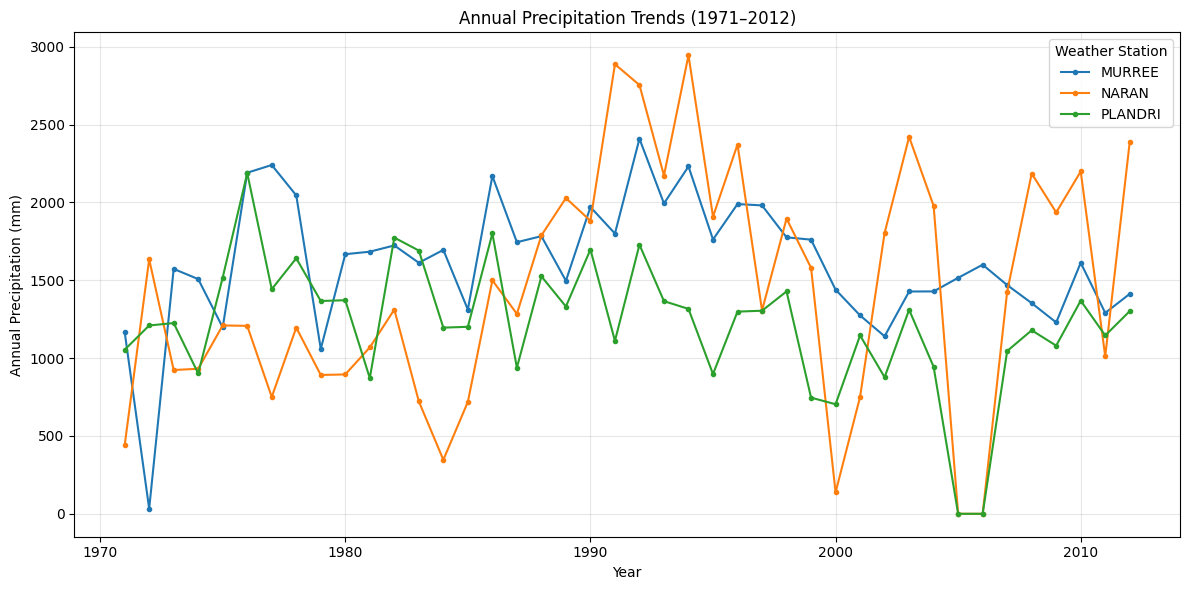

In [ ]:
# Create a figure for annual rainfall trends
plt.figure(figsize=(12, 6))

# Plot annual precipitation for each station
for station in ["MURREE", "NARAN", "PLANDRI"]:

    station_annual = annual_complete[
        annual_complete["Station"] == station
    ].sort_values("Year")

    plt.plot(
        station_annual["Year"],
        station_annual["Annual_Precipitation"],
        marker="o",
        markersize=3,
        label=station
    )

# Add chart title and axis labels
plt.title("Annual Precipitation Trends (1971–2012)")
plt.xlabel("Year")
plt.ylabel("Annual Precipitation (mm)")

# Add legend and grid
plt.legend(title="Weather Station")
plt.grid(alpha=0.3)

# Display the chart
plt.tight_layout()
plt.show()

In [ ]:
# Create an empty dictionary for alert thresholds
alert_thresholds = {}

# Define the training and validation periods
calibration_train = train_imputed[
    train_imputed["Date"].dt.year <= 1999
].copy()

calibration_validation = train_imputed[
    train_imputed["Date"].dt.year >= 2000
].copy()

# Train a calibration model for each station
for station in ["MURREE", "NARAN", "PLANDRI"]:

    # Select station-specific training observations
    station_train = calibration_train[
        calibration_train["Station"] == station
    ]

    # Select station-specific validation observations
    station_validation = calibration_validation[
        calibration_validation["Station"] == station
    ]

    # Prepare training and validation features
    X_cal_train, y_cal_train = create_features(station_train)
    X_cal_validation, y_cal_validation = create_features(
        station_validation
    )

    # Initialize the calibration model
    calibration_model = RandomForestClassifier(
        n_estimators=100,
        random_state=3752,
        class_weight="balanced",
        n_jobs=-1
    )

    # Train the calibration model
    calibration_model.fit(X_cal_train, y_cal_train)

    # Generate rainfall probabilities for validation observations
    rainfall_probabilities = calibration_model.predict_proba(
        X_cal_validation
    )[:, 1]

    # Derive alert thresholds from validation probabilities
    alert_thresholds[station] = {
        "Watch": np.percentile(rainfall_probabilities, 50),
        "Moderate": np.percentile(rainfall_probabilities, 75),
        "High": np.percentile(rainfall_probabilities, 90)
    }

# Display station-specific alert thresholds
print("Training-derived rainfall alert thresholds:")

for station, thresholds in alert_thresholds.items():
    print("\n", station)
    display(pd.DataFrame([thresholds]).round(3))

Training-derived rainfall alert thresholds:

 MURREE


,Watch,Moderate,High
0,0.18,0.36,0.55



 NARAN


,Watch,Moderate,High
0,0.26,0.57,0.84



 PLANDRI


,Watch,Moderate,High
0,0.2,0.42,0.61


In [ ]:
%%writefile -a config.py

# Rainfall alert action descriptions
ALERT_ACTIONS = {
    "Normal": "Continue routine rainfall monitoring.",
    "Watch": "Monitor updated forecasts and local weather conditions.",
    "Moderate": "Increase monitoring and notify the designated focal person.",
    "High": "Issue an urgent warning for human review and approval."
}

Appending to config.py


In [ ]:
%%writefile rules.py

# Import project configuration
import config


def classify_alert(station, probability, thresholds):

    # Retrieve station-specific thresholds
    station_thresholds = thresholds[station]

    # Assign the highest applicable alert level
    if probability >= station_thresholds["High"]:
        alert = "High"

    elif probability >= station_thresholds["Moderate"]:
        alert = "Moderate"

    elif probability >= station_thresholds["Watch"]:
        alert = "Watch"

    else:
        alert = "Normal"

    # Retrieve the corresponding action
    action = config.ALERT_ACTIONS[alert]

    # Return alert level and recommended action
    return alert, action

Writing rules.py


In [ ]:
# Reload the updated configuration module
import importlib
import config

importlib.reload(config)

# Reload the alert rules module
import rules
importlib.reload(rules)

# Import the updated classification function
from rules import classify_alert

# Confirm that alert actions are available
print("Alert actions loaded successfully:")
display(config.ALERT_ACTIONS)

Rain-Guard configuration created successfully.
Alert actions loaded successfully:


{'Normal': 'Continue routine rainfall monitoring.',
 'Watch': 'Monitor updated forecasts and local weather conditions.',
 'Moderate': 'Increase monitoring and notify the designated focal person.',
 'High': 'Issue an urgent warning for human review and approval.'}

In [ ]:
# Test alert classification for each station
test_probabilities = {
    "MURREE": 0.70,
    "NARAN": 0.60,
    "PLANDRI": 0.30
}

# Display alert classifications
for station, probability in test_probabilities.items():

    alert, action = classify_alert(
        station,
        probability,
        alert_thresholds
    )

    print("\nStation:", station)
    print("Rainfall probability:", probability)
    print("Alert level:", alert)
    print("Recommended action:", action)


Station: MURREE
Rainfall probability: 0.7
Alert level: High
Recommended action: Issue an urgent warning for human review and approval.

Station: NARAN
Rainfall probability: 0.6
Alert level: Moderate
Recommended action: Increase monitoring and notify the designated focal person.

Station: PLANDRI
Rainfall probability: 0.3
Alert level: Watch
Recommended action: Monitor updated forecasts and local weather conditions.


In [ ]:
# Import the alert classification function
from rules import classify_alert

# Create an empty list for rainfall alerts
alert_results = []

# Generate predictions for each station
for station in ["MURREE", "NARAN", "PLANDRI"]:

    # Select testing observations for this station
    station_test = test_imputed[
        test_imputed["Station"] == station
    ].copy()

    # Prepare testing features
    X_station, y_station = create_features(station_test)

    # Generate rainfall probabilities
    probabilities = models[station].predict_proba(
        X_station
    )[:, 1]

    # Classify each predicted probability
    for index, probability in enumerate(probabilities):

        alert, action = classify_alert(
            station,
            probability,
            alert_thresholds
        )

        alert_results.append({
            "Date": station_test.iloc[index]["Date"],
            "Station": station,
            "Rainfall_Probability": probability,
            "Alert_Level": alert,
            "Recommended_Action": action,
            "Actual_Rainfall": int(y_station.iloc[index])
        })

# Convert results into a DataFrame
alerts_df = pd.DataFrame(alert_results)

# Display the first ten alerts
print("Rainfall-risk alerts generated successfully:")
display(alerts_df.head(10))

# Display alert counts by station
print("\nAlert distribution by station:")
display(
    alerts_df.groupby(["Station", "Alert_Level"])
    .size()
    .unstack(fill_value=0)
)

Rainfall-risk alerts generated successfully:


,Date,Station,Rainfall_Probability,Alert_Level,Recommended_Action,Actual_Rainfall
0,2005-01-01,MURREE,0.86,High,Issue an urgent warning for human review and a...,1
1,2005-01-02,MURREE,0.44,Moderate,Increase monitoring and notify the designated ...,0
2,2005-01-03,MURREE,0.26,Watch,Monitor updated forecasts and local weather co...,0
3,2005-01-04,MURREE,0.08,Normal,Continue routine rainfall monitoring.,0
4,2005-01-05,MURREE,0.35,Watch,Monitor updated forecasts and local weather co...,0
5,2005-01-06,MURREE,0.20,Watch,Monitor updated forecasts and local weather co...,0
6,2005-01-08,MURREE,0.16,Normal,Continue routine rainfall monitoring.,0
7,2005-01-09,MURREE,0.04,Normal,Continue routine rainfall monitoring.,1
8,2005-01-10,MURREE,0.19,Watch,Monitor updated forecasts and local weather co...,0
9,2005-01-11,MURREE,0.09,Normal,Continue routine rainfall monitoring.,0



Alert distribution by station:


Alert_Level,High,Moderate,Normal,Watch
Station,,,,
MURREE,577,464,1144,579
NARAN,233,422,1367,762
PLANDRI,331,405,1385,658


In [ ]:
# Create an empty dictionary for station status
station_status = {}

# Get the latest alert for each station
for station in ["MURREE", "NARAN", "PLANDRI"]:

    # Select the station's alert records
    station_alerts = alerts_df[
        alerts_df["Station"] == station
    ].sort_values("Date")

    # Retrieve the latest record
    latest_alert = station_alerts.iloc[-1]

    # Store the latest station status
    station_status[station] = {
        "Date": latest_alert["Date"].strftime("%Y-%m-%d"),
        "Rainfall_Probability": round(
            float(latest_alert["Rainfall_Probability"]), 3
        ),
        "Alert_Level": latest_alert["Alert_Level"],
        "Recommended_Action": latest_alert["Recommended_Action"]
    }

# Save station status as JSON
with open("status.json", "w") as file:
    json.dump(station_status, file, indent=4)

# Display the generated status
print("status.json created successfully.")

with open("status.json", "r") as file:
    print(file.read())

status.json created successfully.
{
    "MURREE": {
        "Date": "2012-12-30",
        "Rainfall_Probability": 0.03,
        "Alert_Level": "Normal",
        "Recommended_Action": "Continue routine rainfall monitoring."
    },
    "NARAN": {
        "Date": "2012-12-29",
        "Rainfall_Probability": 0.81,
        "Alert_Level": "Moderate",
        "Recommended_Action": "Increase monitoring and notify the designated focal person."
    },
    "PLANDRI": {
        "Date": "2012-12-30",
        "Rainfall_Probability": 0.29,
        "Alert_Level": "Watch",
        "Recommended_Action": "Monitor updated forecasts and local weather conditions."
    }
}


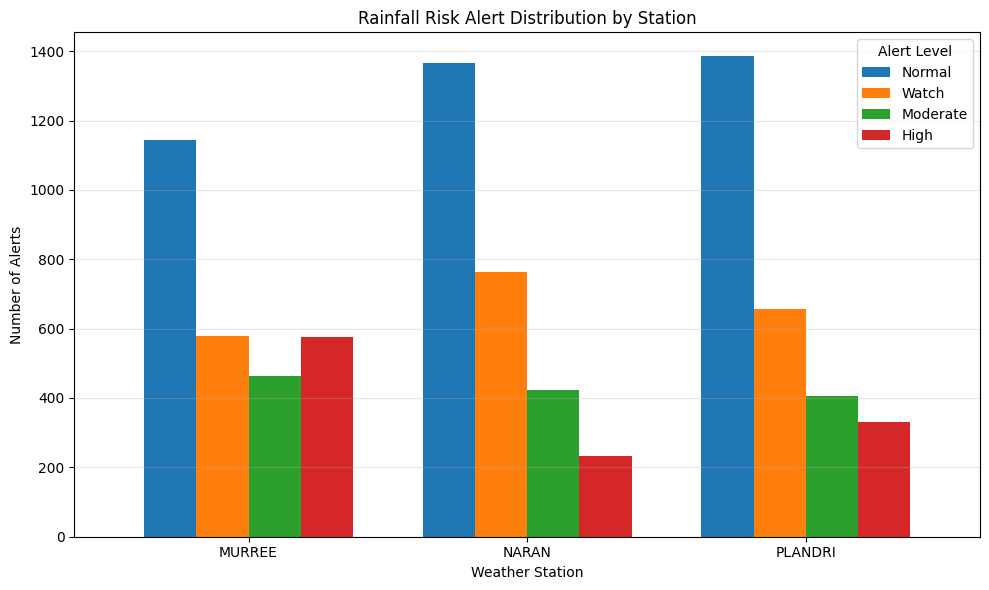

Rainfall-risk chart saved correctly.


In [ ]:
# Recreate the rainfall-risk chart
fig, ax = plt.subplots(figsize=(10, 6))

# Plot alert counts
alert_counts.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

# Add chart title and labels
ax.set_title("Rainfall Risk Alert Distribution by Station")
ax.set_xlabel("Weather Station")
ax.set_ylabel("Number of Alerts")

# Format the chart
ax.legend(title="Alert Level")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

# Adjust chart layout
fig.tight_layout()

# Save the chart before displaying it
fig.savefig(
    "rainfall_risk_chart.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

print("Rainfall-risk chart saved correctly.")

In [ ]:
# Create an empty list for the High-alert scorecard
scorecard_results = []

# Evaluate each station
for station in ["MURREE", "NARAN", "PLANDRI"]:

    # Select station testing observations
    station_alerts = alerts_df[
        alerts_df["Station"] == station
    ].copy()

    # Identify High alerts
    predicted_high = (
        station_alerts["Alert_Level"] == "High"
    ).astype(int)

    # Identify actual rainfall events
    actual_rain = station_alerts["Actual_Rainfall"]

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        actual_rain,
        predicted_high,
        labels=[0, 1]
    ).ravel()

    # Calculate performance rates
    hit_rate = tp / (tp + fn) if (tp + fn) > 0 else 0
    false_alarm_rate = fp / (fp + tn) if (fp + tn) > 0 else 0
    miss_rate = fn / (tp + fn) if (tp + fn) > 0 else 0

    # Store results
    scorecard_results.append({
        "Station": station,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn,
        "Hit Rate": hit_rate,
        "False-Alarm Rate": false_alarm_rate,
        "Miss Rate": miss_rate
    })

# Calculate overall results across all stations
tn, fp, fn, tp = confusion_matrix(
    alerts_df["Actual_Rainfall"],
    (alerts_df["Alert_Level"] == "High").astype(int),
    labels=[0, 1]
).ravel()

scorecard_results.append({
    "Station": "OVERALL",
    "True Positives": tp,
    "False Positives": fp,
    "True Negatives": tn,
    "False Negatives": fn,
    "Hit Rate": tp / (tp + fn),
    "False-Alarm Rate": fp / (fp + tn),
    "Miss Rate": fn / (tp + fn)
})

# Display the High-alert scorecard
scorecard_df = pd.DataFrame(scorecard_results)

print("High-alert performance scorecard (2005–2012):")
display(scorecard_df.round(3))

High-alert performance scorecard (2005–2012):


,Station,True Positives,False Positives,True Negatives,False Negatives,Hit Rate,False-Alarm Rate,Miss Rate
0,MURREE,408,169,1658,529,0.435,0.093,0.565
1,NARAN,170,63,2058,493,0.256,0.030,0.744
2,PLANDRI,123,208,2103,345,0.263,0.090,0.737
3,OVERALL,701,440,5819,1367,0.339,0.070,0.661


In [ ]:
%%writefile test_agent.py

# Import required libraries
import unittest
import pandas as pd
import numpy as np
import os
import json

# Import project modules
import config
from collector import basic_quality_control, create_next_day_target, split_data_strict
from features import create_features
from rules import classify_alert


class TestRainGuardAgent(unittest.TestCase):

    # Test 1: Temperature placeholders are removed
    def test_temperature_placeholders(self):
        sample = pd.DataFrame({
            "Max": [25, 100, 30],
            "Min": [10, 15, -99.9],
            "Precipitation": [2, 0, 5]
        })

        cleaned, log = basic_quality_control(sample)

        self.assertTrue(cleaned["Max"].isna().sum() == 1)
        self.assertTrue(cleaned["Min"].isna().sum() == 1)

    # Test 2: Negative precipitation is removed
    def test_negative_precipitation(self):
        sample = pd.DataFrame({
            "Max": [25, 30],
            "Min": [10, 15],
            "Precipitation": [-2, 5]
        })

        cleaned, log = basic_quality_control(sample)

        self.assertTrue(cleaned["Precipitation"].isna().sum() == 1)

    # Test 3: Next-day target is correctly aligned
    def test_next_day_target(self):
        sample = pd.DataFrame({
            "Date": pd.to_datetime([
                "2000-01-01",
                "2000-01-02",
                "2000-01-03"
            ]),
            "Station": ["MURREE"] * 3,
            "Precipitation": [0, 5, 0],
            "Max": [20, 21, 22],
            "Min": [10, 11, 12]
        })

        result = create_next_day_target(sample)

        self.assertEqual(
            result["Raintomorrow"].tolist(),
            [1, 0]
        )

    # Test 4: Training and testing dates do not overlap
    def test_chronological_split(self):
        sample = pd.DataFrame({
            "Date": pd.to_datetime([
                "2004-12-30",
                "2005-01-01"
            ]),
            "Station": ["MURREE", "MURREE"]
        })

        train, test = split_data_strict(sample)

        self.assertTrue(
            train["Date"].max() < test["Date"].min()
        )

    # Test 5: Target is not included among predictors
    def test_no_target_leakage(self):
        sample = pd.DataFrame({
            "Date": pd.to_datetime(["2000-01-01"]),
            "Precipitation": [5],
            "Max": [20],
            "Min": [10],
            "Raintomorrow": [1]
        })

        X, y = create_features(sample)

        self.assertNotIn("Raintomorrow", X.columns)
        self.assertEqual(len(X.columns), 5)

    # Test 6: Alert classification returns a valid level
    def test_alert_classification(self):
        thresholds = {
            "MURREE": {
                "Watch": 0.18,
                "Moderate": 0.36,
                "High": 0.55
            }
        }

        alert, action = classify_alert(
            "MURREE",
            0.70,
            thresholds
        )

        self.assertEqual(alert, "High")
        self.assertTrue(len(action) > 0)

    # Test 7: Status JSON exists and is readable
    def test_status_file(self):
        self.assertTrue(os.path.exists("status.json"))

        with open("status.json", "r") as file:
            status = json.load(file)

        self.assertTrue(
            all(station in status for station in config.STATIONS)
        )


# Run all automated tests
if __name__ == "__main__":
    unittest.main(argv=[""], exit=False, verbosity=2)

Writing test_agent.py


In [ ]:
# Import the testing library
import unittest
import importlib

# Reload the automated testing module
importlib.reload(test_agent)

# Load all automated tests
test_suite = unittest.TestLoader().loadTestsFromModule(test_agent)

# Run the tests
test_runner = unittest.TextTestRunner(verbosity=2)
test_runner.run(test_suite)

test_alert_classification (test_agent.TestRainGuardAgent.test_alert_classification) ... ok
test_chronological_split (test_agent.TestRainGuardAgent.test_chronological_split) ... ok
test_negative_precipitation (test_agent.TestRainGuardAgent.test_negative_precipitation) ... ok
test_next_day_target (test_agent.TestRainGuardAgent.test_next_day_target) ... ok
test_no_target_leakage (test_agent.TestRainGuardAgent.test_no_target_leakage) ... ok
test_status_file (test_agent.TestRainGuardAgent.test_status_file) ... ok
test_temperature_placeholders (test_agent.TestRainGuardAgent.test_temperature_placeholders) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.111s

OK


<unittest.runner.TextTestResult run=7 errors=0 failures=0>

In [ ]:
%%writefile report.py

# Import required libraries
import pandas as pd


def generate_report(
    evaluation_df,
    unseen_results,
    trend_results_df,
    scorecard_df
):

    # Display model evaluation results
    print("\nRAIN-GUARD MODEL EVALUATION")
    print("=" * 50)
    display(evaluation_df)

    # Display unseen-station generalization results
    print("\nUNSEEN-STATION GENERALIZATION")
    print("=" * 50)
    display(pd.DataFrame([unseen_results]))

    # Display rainfall trend analysis
    print("\nRAINFALL TREND ANALYSIS")
    print("=" * 50)
    display(trend_results_df)

    # Display High-alert scorecard
    print("\nHIGH-ALERT PERFORMANCE SCORECARD")
    print("=" * 50)
    display(scorecard_df)

    # Save evaluation tables
    evaluation_df.to_csv("model_evaluation.csv", index=False)
    trend_results_df.to_csv("rainfall_trends.csv", index=False)
    scorecard_df.to_csv("high_alert_scorecard.csv", index=False)

    print("\nReport tables saved successfully.")

Writing report.py


In [ ]:
# Import the reporting function
from report import generate_report

# Generate the consolidated Rain-Guard report
generate_report(
    evaluation_df,
    unseen_results,
    trend_results_df,
    scorecard_df
)


RAIN-GUARD MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1-score
0,MURREE,0.746744,0.682028,0.473853,0.559194
1,NARAN,0.794181,0.558290,0.650075,0.600697
2,PLANDRI,0.773660,0.343689,0.378205,0.360122
3,POOLED,0.765942,0.532355,0.473404,0.501152



UNSEEN-STATION GENERALIZATION


,Training stations,Unseen test station,Accuracy,Precision,Recall,F1-score
0,"MURREE, NARAN",PLANDRI,0.822958,0.448718,0.224359,0.299145



RAINFALL TREND ANALYSIS


,Station,Years analysed,Kendall's tau,p-value,Sen's slope (mm/year),Trend
0,MURREE,42,-0.108014,0.313513,-4.835702,No significant trend
1,NARAN,42,0.260314,0.015194,25.929517,Increasing
2,PLANDRI,42,-0.248693,0.020377,-9.700000,Decreasing



HIGH-ALERT PERFORMANCE SCORECARD


,Station,True Positives,False Positives,True Negatives,False Negatives,Hit Rate,False-Alarm Rate,Miss Rate
0,MURREE,408,169,1658,529,0.435432,0.092501,0.564568
1,NARAN,170,63,2058,493,0.256410,0.029703,0.743590
2,PLANDRI,123,208,2103,345,0.262821,0.090004,0.737179
3,OVERALL,701,440,5819,1367,0.338975,0.070299,0.661025



Report tables saved successfully.


In [ ]:
%%writefile report.py

# Import required libraries
import pandas as pd
from IPython.display import display


def generate_report(
    evaluation_df,
    unseen_results,
    trend_results_df,
    scorecard_df
):

    # Display model evaluation results
    print("\nRAIN-GUARD MODEL EVALUATION")
    display(evaluation_df)

    # Display unseen-station generalization results
    print("\nUNSEEN-STATION GENERALIZATION")
    display(pd.DataFrame([unseen_results]))

    # Display rainfall trend analysis
    print("\nRAINFALL TREND ANALYSIS")
    display(trend_results_df)

    # Display High-alert scorecard
    print("\nHIGH-ALERT PERFORMANCE SCORECARD")
    display(scorecard_df)

    # Save evaluation tables
    evaluation_df.to_csv("model_evaluation.csv", index=False)
    trend_results_df.to_csv("rainfall_trends.csv", index=False)
    scorecard_df.to_csv("high_alert_scorecard.csv", index=False)

    print("\nReport tables saved successfully.")

Overwriting report.py


In [ ]:
%%writefile -a config.py

# Random Forest model settings
N_ESTIMATORS = 100
CLASS_WEIGHT = "balanced"

# Annual rainfall trend analysis
ANNUAL_COVERAGE_THRESHOLD = 0.90

# Alert threshold calibration percentiles
ALERT_PERCENTILES = {
    "Watch": 50,
    "Moderate": 75,
    "High": 90
}

# Station-specific alert probability thresholds
ALERT_THRESHOLDS = {
    "MURREE": {
        "Watch": 0.18,
        "Moderate": 0.36,
        "High": 0.55
    },
    "NARAN": {
        "Watch": 0.26,
        "Moderate": 0.57,
        "High": 0.84
    },
    "PLANDRI": {
        "Watch": 0.20,
        "Moderate": 0.42,
        "High": 0.61
    }
}

Appending to config.py


In [ ]:
# Reload the updated configuration
import importlib
import config

importlib.reload(config)

# Display the model settings
print("Random seed:", config.RANDOM_STATE)
print("Number of trees:", config.N_ESTIMATORS)
print("MAD threshold:", config.MAD_THRESHOLD)

# Display alert thresholds
print("\nStation-specific alert thresholds:")
for station, thresholds in config.ALERT_THRESHOLDS.items():
    print(station, thresholds)

# Confirm configuration
print("\nConfiguration verified successfully.")

Rain-Guard configuration created successfully.
Random seed: 3752
Number of trees: 100
MAD threshold: 3.5

Station-specific alert thresholds:
MURREE {'Watch': 0.18, 'Moderate': 0.36, 'High': 0.55}
NARAN {'Watch': 0.26, 'Moderate': 0.57, 'High': 0.84}
PLANDRI {'Watch': 0.2, 'Moderate': 0.42, 'High': 0.61}

Configuration verified successfully.


In [ ]:
%%writefile run_agent.py

# Import required libraries
import pandas as pd
import numpy as np
import json
import os

# Import project modules
import config
from collector import (
    load_data,
    basic_quality_control,
    detect_monthly_outliers,
    create_next_day_target,
    split_data_strict,
    impute_missing_values
)
from features import create_features
from models import train_random_forest_models
from rules import classify_alert
from report import generate_report

# Main agent execution function
def run_agent():

    # Load the original weather dataset
    raw_data = load_data()

    # Apply basic data quality control
    cleaned_data, qc_log = basic_quality_control(raw_data)

    # Detect monthly statistical outliers
    cleaned_data, outlier_report = detect_monthly_outliers(cleaned_data)

    # Construct the next-day rainfall prediction target
    model_data = create_next_day_target(cleaned_data)

    # Split observations chronologically
    train_data, test_data = split_data_strict(model_data)

    # Impute missing weather values using training data only
    train_data, test_data, imputation_log = impute_missing_values(
        train_data,
        test_data
    )

    # Display initial pipeline results
    print("RAIN-GUARD DATA PIPELINE")
    print("=" * 50)
    print("Selected stations:", config.STATIONS)
    print("Random seed:", config.RANDOM_STATE)
    print("Training observations:", len(train_data))
    print("Testing observations:", len(test_data))
    print("Data processing completed.")

Writing run_agent.py


In [ ]:
%%writefile -a run_agent.py

    # Train station-specific and pooled Random Forest models
    models = train_random_forest_models(train_data)

    # Store model evaluation results
    evaluation_results = []

    # Evaluate each station-specific model
    for station in config.STATIONS:

        station_test = test_data[
            test_data["Station"] == station
        ]

        X_test, y_test = create_features(station_test)

        predictions = models[station].predict(X_test)

        from sklearn.metrics import (
            accuracy_score,
            precision_score,
            recall_score,
            f1_score
        )

        evaluation_results.append({
            "Model": station,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1-score": f1_score(y_test, predictions, zero_division=0)
        })

    # Evaluate the pooled model
    X_test, y_test = create_features(test_data)
    pooled_predictions = models["POOLED"].predict(X_test)

    evaluation_results.append({
        "Model": "POOLED",
        "Accuracy": accuracy_score(y_test, pooled_predictions),
        "Precision": precision_score(y_test, pooled_predictions, zero_division=0),
        "Recall": recall_score(y_test, pooled_predictions, zero_division=0),
        "F1-score": f1_score(y_test, pooled_predictions, zero_division=0)
    })

    evaluation_df = pd.DataFrame(evaluation_results)

    # Test generalization to a station excluded from model training
    unseen_train = train_data[
        train_data["Station"].isin(["MURREE", "NARAN"])
    ]

    unseen_test = test_data[
        test_data["Station"] == "PLANDRI"
    ]

    X_unseen_train, y_unseen_train = create_features(unseen_train)
    X_unseen_test, y_unseen_test = create_features(unseen_test)

    from sklearn.ensemble import RandomForestClassifier

    unseen_model = RandomForestClassifier(
        n_estimators=config.N_ESTIMATORS,
        random_state=config.RANDOM_STATE,
        class_weight=config.CLASS_WEIGHT,
        n_jobs=-1
    )

    unseen_model.fit(X_unseen_train, y_unseen_train)
    unseen_predictions = unseen_model.predict(X_unseen_test)

    unseen_results = {
        "Training stations": "MURREE, NARAN",
        "Unseen test station": "PLANDRI",
        "Accuracy": accuracy_score(y_unseen_test, unseen_predictions),
        "Precision": precision_score(y_unseen_test, unseen_predictions, zero_division=0),
        "Recall": recall_score(y_unseen_test, unseen_predictions, zero_division=0),
        "F1-score": f1_score(y_unseen_test, unseen_predictions, zero_division=0)
    }

    print("Model training and evaluation completed.")
    print(evaluation_df)
    print("\nUnseen-station results:")
    print(unseen_results)

Appending to run_agent.py


In [ ]:
%%writefile -a run_agent.py

    # Calculate annual rainfall totals
    trend_data = cleaned_data.copy()
    trend_data["Year"] = trend_data["Date"].dt.year

    annual_data = (
        trend_data.groupby(["Station", "Year"])
        .agg(
            Annual_Precipitation=("Precipitation", "sum"),
            Observed_Days=("Precipitation", "count")
        )
        .reset_index()
    )

    # Import statistical analysis functions
    from scipy.stats import kendalltau, theilslopes

    trend_results = []

    # Analyse rainfall trends for each station
    for station in config.STATIONS:

        station_annual = annual_data[
            annual_data["Station"] == station
        ].copy()

        # Retain years with at least 90% data coverage
        station_annual = station_annual[
            station_annual["Observed_Days"] >=
            365 * config.ANNUAL_COVERAGE_THRESHOLD
        ]

        years = station_annual["Year"].values
        rainfall = station_annual["Annual_Precipitation"].values

        # Apply Kendall trend test and Sen's slope
        tau, p_value = kendalltau(years, rainfall)
        sen_slope = theilslopes(rainfall, years)[0]

        # Classify the observed trend
        if p_value < 0.05 and sen_slope > 0:
            trend = "Increasing"
        elif p_value < 0.05 and sen_slope < 0:
            trend = "Decreasing"
        else:
            trend = "No significant trend"

        trend_results.append({
            "Station": station,
            "Years analysed": len(years),
            "Kendall's tau": tau,
            "p-value": p_value,
            "Sen's slope (mm/year)": sen_slope,
            "Trend": trend
        })

    trend_results_df = pd.DataFrame(trend_results)

    print("\nRainfall trend analysis completed.")
    print(trend_results_df)

Appending to run_agent.py


In [ ]:
%%writefile -a run_agent.py

    # Generate rainfall risk alerts
    alert_records = []

    for station in config.STATIONS:

        station_test = test_data[
            test_data["Station"] == station
        ].copy()

        X_station, y_station = create_features(station_test)

        # Calculate next-day rainfall probabilities
        probabilities = models[station].predict_proba(X_station)[:, 1]

        # Classify each prediction
        for index, probability in enumerate(probabilities):

            alert, action = classify_alert(
                station,
                probability,
                config.ALERT_THRESHOLDS
            )

            alert_records.append({
                "Date": station_test.iloc[index]["Date"],
                "Station": station,
                "Rainfall_Probability": probability,
                "Alert_Level": alert,
                "Recommended_Action": action,
                "Actual_Rainfall": int(y_station.iloc[index])
            })

    alerts_df = pd.DataFrame(alert_records)

    # Save the latest available status for each station
    latest_status = {}

    for station in config.STATIONS:

        station_alerts = alerts_df[
            alerts_df["Station"] == station
        ].sort_values("Date")

        latest = station_alerts.iloc[-1]

        latest_status[station] = {
            "Date": latest["Date"].strftime("%Y-%m-%d"),
            "Rainfall_Probability": round(
                float(latest["Rainfall_Probability"]), 3
            ),
            "Alert_Level": latest["Alert_Level"],
            "Recommended_Action": latest["Recommended_Action"]
        }

    # Write the station statuses to a JSON file
    with open("status.json", "w") as file:
        json.dump(latest_status, file, indent=4)

    print("\nAlert generation completed.")
    print(alerts_df["Alert_Level"].value_counts())
    print("\nLatest station statuses:")
    print(json.dumps(latest_status, indent=4))

Appending to run_agent.py


In [ ]:
%%writefile -a run_agent.py

    # Calculate High-alert performance
    scorecard_records = []

    for station in config.STATIONS:

        station_alerts = alerts_df[
            alerts_df["Station"] == station
        ]

        # Identify High alerts and actual rainfall events
        high_alert = (
            station_alerts["Alert_Level"] == "High"
        )

        actual_rain = (
            station_alerts["Actual_Rainfall"] == 1
        )

        # Calculate confusion matrix components
        TP = int((high_alert & actual_rain).sum())
        FP = int((high_alert & ~actual_rain).sum())
        TN = int((~high_alert & ~actual_rain).sum())
        FN = int((~high_alert & actual_rain).sum())

        # Calculate performance rates
        hit_rate = TP / (TP + FN) if TP + FN else 0
        false_alarm_rate = FP / (FP + TN) if FP + TN else 0
        miss_rate = FN / (TP + FN) if TP + FN else 0

        scorecard_records.append({
            "Station": station,
            "True Positives": TP,
            "False Positives": FP,
            "True Negatives": TN,
            "False Negatives": FN,
            "Hit Rate": hit_rate,
            "False-Alarm Rate": false_alarm_rate,
            "Miss Rate": miss_rate
        })

    # Calculate overall scorecard
    overall = {
        "Station": "OVERALL",
        "True Positives": sum(r["True Positives"] for r in scorecard_records),
        "False Positives": sum(r["False Positives"] for r in scorecard_records),
        "True Negatives": sum(r["True Negatives"] for r in scorecard_records),
        "False Negatives": sum(r["False Negatives"] for r in scorecard_records)
    }

    overall["Hit Rate"] = (
        overall["True Positives"] /
        (overall["True Positives"] + overall["False Negatives"])
    )

    overall["False-Alarm Rate"] = (
        overall["False Positives"] /
        (overall["False Positives"] + overall["True Negatives"])
    )

    overall["Miss Rate"] = (
        overall["False Negatives"] /
        (overall["True Positives"] + overall["False Negatives"])
    )

    scorecard_records.append(overall)

    scorecard_df = pd.DataFrame(scorecard_records)

    print("\nHigh-alert performance scorecard:")
    print(scorecard_df)

Appending to run_agent.py


In [ ]:
%%writefile -a run_agent.py

    # Generate rainfall risk distribution chart
    import matplotlib.pyplot as plt

    alert_counts = pd.crosstab(
        alerts_df["Station"],
        alerts_df["Alert_Level"]
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    alert_counts.plot(kind="bar", ax=ax, width=0.75)

    ax.set_title("Rainfall Risk Alert Distribution by Station")
    ax.set_xlabel("Weather Station")
    ax.set_ylabel("Number of Alerts")
    ax.legend(title="Alert Level")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    fig.savefig(
        "rainfall_risk_chart.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

    # Save quality-control and outlier reports
    qc_log.to_csv("quality_control_log.csv", index=False)
    outlier_report.to_csv("outlier_report.csv", index=False)
    imputation_log.to_csv("imputation_log.csv", index=False)

    # Generate the consolidated analysis report
    generate_report(
        evaluation_df,
        unseen_results,
        trend_results_df,
        scorecard_df
    )

    # Save all generated alerts
    alerts_df.to_csv("rainfall_alerts.csv", index=False)

    # Display final completion message
    print("\n" + "=" * 50)
    print("RAIN-GUARD AGENT EXECUTION COMPLETED")
    print("=" * 50)
    print("Generated outputs:")
    print("- status.json")
    print("- rainfall_risk_chart.png")
    print("- rainfall_alerts.csv")
    print("- quality_control_log.csv")
    print("- outlier_report.csv")
    print("- imputation_log.csv")
    print("- model_evaluation.csv")
    print("- rainfall_trends.csv")
    print("- high_alert_scorecard.csv")


# Run the agent when this script is executed directly
if __name__ == "__main__":
    run_agent()

Appending to run_agent.py


In [ ]:
%%writefile report.py

# Import required libraries
import pandas as pd


def generate_report(
    evaluation_df,
    unseen_results,
    trend_results_df,
    scorecard_df
):

    # Display model evaluation results
    print("\nRAIN-GUARD MODEL EVALUATION")
    print("=" * 50)
    print(evaluation_df.to_string(index=False))

    # Display unseen-station generalization results
    print("\nUNSEEN-STATION GENERALIZATION")
    print("=" * 50)
    print(pd.DataFrame([unseen_results]).to_string(index=False))

    # Display rainfall trend analysis
    print("\nRAINFALL TREND ANALYSIS")
    print("=" * 50)
    print(trend_results_df.to_string(index=False))

    # Display High-alert scorecard
    print("\nHIGH-ALERT PERFORMANCE SCORECARD")
    print("=" * 50)
    print(scorecard_df.to_string(index=False))

    # Save evaluation tables
    evaluation_df.to_csv("model_evaluation.csv", index=False)
    trend_results_df.to_csv("rainfall_trends.csv", index=False)
    scorecard_df.to_csv("high_alert_scorecard.csv", index=False)

    print("\nReport tables saved successfully.")

Overwriting report.py


In [ ]:
# Execute the complete Rain-Guard Agent
!python run_agent.py

Rain-Guard configuration created successfully.
RAIN-GUARD DATA PIPELINE
Selected stations: ['MURREE', 'NARAN', 'PLANDRI']
Random seed: 3752
Training observations: 35410
Testing observations: 8327
Data processing completed.
Model training and evaluation completed.
     Model  Accuracy  Precision    Recall  F1-score
0   MURREE  0.746744   0.682028  0.473853  0.559194
1    NARAN  0.794181   0.558290  0.650075  0.600697
2  PLANDRI  0.773660   0.343689  0.378205  0.360122
3   POOLED  0.765942   0.532355  0.473404  0.501152

Unseen-station results:
{'Training stations': 'MURREE, NARAN', 'Unseen test station': 'PLANDRI', 'Accuracy': 0.8229578985246492, 'Precision': 0.44871794871794873, 'Recall': 0.22435897435897437, 'F1-score': 0.29914529914529914}

Rainfall trend analysis completed.
   Station  Years analysed  ...  Sen's slope (mm/year)                 Trend
0   MURREE              42  ...              -4.835702  No significant trend
1    NARAN              42  ...              25.929517    

In [ ]:
# Import file-management library
import os

# Create the project directory
project_folder = "Rain_Guard_Agent"
os.makedirs(project_folder, exist_ok=True)

# Display confirmation
print("Project folder created:", project_folder)

Project folder created: Rain_Guard_Agent


In [ ]:
# Import file-management library
import shutil

# Define project files
project_files = [
    "config.py",
    "collector.py",
    "features.py",
    "models.py",
    "rules.py",
    "report.py",
    "run_agent.py",
    "test_agent.py",
    "Data_Input.xlsx",
    "status.json",
    "rainfall_risk_chart.png",
    "rainfall_alerts.csv",
    "quality_control_log.csv",
    "outlier_report.csv",
    "imputation_log.csv",
    "model_evaluation.csv",
    "rainfall_trends.csv",
    "high_alert_scorecard.csv"
]

# Copy files into the project folder
for file in project_files:
    if os.path.exists(file):
        shutil.copy2(
            file,
            os.path.join(project_folder, file)
        )
        print("Copied:", file)
    else:
        print("Missing:", file)

print("\nProject files organized.")

Copied: config.py
Copied: collector.py
Copied: features.py
Copied: models.py
Copied: rules.py
Copied: report.py
Copied: run_agent.py
Copied: test_agent.py
Copied: Data_Input.xlsx
Copied: status.json
Copied: rainfall_risk_chart.png
Copied: rainfall_alerts.csv
Copied: quality_control_log.csv
Copied: outlier_report.csv
Copied: imputation_log.csv
Copied: model_evaluation.csv
Copied: rainfall_trends.csv
Copied: high_alert_scorecard.csv

Project files organized.


In [ ]:

# Import libraries
import os
import pandas as pd
import matplotlib.pyplot as plt

# Define project folder
folder = "Rain_Guard_Agent"

# Load the generated evaluation tables
evaluation = pd.read_csv(
    os.path.join(folder, "model_evaluation.csv")
)

trends = pd.read_csv(
    os.path.join(folder, "rainfall_trends.csv")
)

scorecard = pd.read_csv(
    os.path.join(folder, "high_alert_scorecard.csv")
)

alerts = pd.read_csv(
    os.path.join(folder, "rainfall_alerts.csv")
)

# GRAPH 1: Model performance
fig, ax = plt.subplots(figsize=(7, 3.5))

evaluation.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", ax=ax)

ax.set_title("Random Forest Model Performance (2005–2012)")
ax.set_xlabel("Model")
ax.set_ylabel("Performance Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right", fontsize=8)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    os.path.join(folder, "model_performance.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.close(fig)

# GRAPH 2: Annual rainfall trend slopes
fig, ax = plt.subplots(figsize=(6, 3))

ax.bar(
    trends["Station"],
    trends["Sen's slope (mm/year)"]
)

ax.axhline(0, linewidth=0.8)
ax.set_title("Estimated Annual Rainfall Trend by Station")
ax.set_xlabel("Weather Station")
ax.set_ylabel("Sen's Slope (mm/year)")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    os.path.join(folder, "rainfall_trends.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.close(fig)

# GRAPH 3: Rainfall alert distribution
alert_counts = pd.crosstab(
    alerts["Station"],
    alerts["Alert_Level"]
)

alert_order = ["Normal", "Watch", "Moderate", "High"]
alert_counts = alert_counts.reindex(
    columns=alert_order,
    fill_value=0
)

fig, ax = plt.subplots(figsize=(7, 3.5))

alert_counts.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title("Rainfall Risk Alert Distribution by Station (2005–2012)")
ax.set_xlabel("Weather Station")
ax.set_ylabel("Number of Alerts")
ax.legend(title="Alert Level", fontsize=8)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    os.path.join(folder, "rainfall_alert_distribution.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.close(fig)

# Prepare formatted results tables
model_table = evaluation.to_markdown(index=False, floatfmt=".3f")
trend_table = trends.to_markdown(index=False, floatfmt=".3f")

overall = scorecard[
    scorecard["Station"] == "OVERALL"
].iloc[0]

# Write the complete README from scratch
readme = """# **Rain-Guard Agent: Project**

Yasir Rauf

Faculty of Arts and Sciences (FAS), Aga Khan University (AKU), Karachi, Pakistan

**Student ID:** 593752

**Assigned Station:** MURREE, NARAN, PLANDRI

**Random seed:** 3752

**Training Period:** 1971–2004

**Testing Period:** 2005–2012

Following the five-layer K-WaterGuard structure from the workshop (configure, perceive, reason, act, orchestrate), this project builds Rain-Guard, a daily rainfall-risk agent for MURREE, NARAN, and PLANDRI using seed 3752 and a 1971–2004 training / 2005–2012 testing split. It cleans station weather data, forecasts next-day rain alongside annual precipitation trends, and assigns alert tiers with clear actions. Everything runs from a single command to produce a status file and a chart, supported by automated tests, a highest-tier scorecard, and a human-approval safeguard.

## 1. Configure and Perceive: Data Preparation

The project used the supplied daily weather dataset (1971–2012), containing precipitation, maximum and minimum temperature, station identifiers, and rainfall labels. The three assigned stations were selected using the student-ID procedure.

Data quality control replaced temperature placeholders and negative precipitation values with missing values. Monthly median absolute deviation (MAD) was used to flag potential outliers without automatically deleting extreme observations. Missing weather predictors were imputed using training-period medians.

The original rainfall label was reconstructed using precipitation on the following calendar day. Observations without a consecutive next-day record or valid next-day precipitation were excluded. This ensured that the prediction target represented next-day rainfall rather than same-day rainfall.

Five predictors were used: precipitation, maximum temperature, minimum temperature, and seasonal sine and cosine terms. The final dataset contained **35,410 training observations** and **8,327 testing observations**. The training and testing periods were kept chronological, with no overlap.

## 2. Reason: Model Development and Evaluation

Four Random Forest models were developed: one for each station and one pooled model trained on all three stations. Models used 100 trees, a fixed random seed of 3752, and balanced class weights.

### Table 1. Random Forest Model Performance on the Testing Period

""" + model_table + """

NARAN achieved the highest F1-score (0.601), followed by MURREE (0.559), the pooled model (0.501), and PLANDRI (0.360). PLANDRI's comparatively low precision and recall indicate weaker identification of next-day rainfall events.

![Random Forest model performance](model_performance.png)

*Figure 1. Accuracy, precision, recall, and F1-score for the four models.*

### Unseen-station generalization

A separate model was trained using MURREE and NARAN and evaluated exclusively on PLANDRI, which was excluded from training. It achieved **0.823 accuracy, 0.449 precision, 0.224 recall, and 0.299 F1-score**. Although overall accuracy was relatively high, the low recall demonstrates limited detection of rainfall events at an unseen station.

## 3. Reason: Historical Rainfall Trend Analysis

Annual precipitation totals were analysed for 42 years per station using Kendall's tau-based trend testing and Sen's slope. Years with less than 90% daily observation coverage were excluded.

### Table 2. Annual Rainfall Trend Results

""" + trend_table + """

NARAN showed a statistically significant increasing trend, while PLANDRI showed a statistically significant decreasing trend. MURREE had no statistically significant trend at the 0.05 level.

![Annual rainfall trends](rainfall_trends.png)

*Figure 2. Sen's estimated annual precipitation trend slopes. Positive values indicate increasing rainfall and negative values indicate decreasing rainfall.*

These findings describe historical associations, not causes or future rainfall projections. Conventional significance estimates may also be affected by serial correlation in annual precipitation.

## 4. Act: Risk Classification and Alert Evaluation

Predicted rainfall probabilities were classified into four tiers: Normal, Watch, Moderate, and High. Station-specific thresholds were calibrated using training-period validation data and stored in `config.py`. Each tier has a corresponding recommended action.

![Rainfall alert distribution](rainfall_alert_distribution.png)

*Figure 3. Distribution of the four rainfall-risk alert levels across the three stations during testing.*

### Table 3. Overall High-Alert Performance (2005–2012)

| Measure | Result |
|---|---:|
| True positives | """ + f"{int(overall['True Positives']):,}" + """ |
| False positives | """ + f"{int(overall['False Positives']):,}" + """ |
| True negatives | """ + f"{int(overall['True Negatives']):,}" + """ |
| False negatives | """ + f"{int(overall['False Negatives']):,}" + """ |
| Hit rate | """ + f"{overall['Hit Rate']:.3f}" + """ |
| False-alarm rate | """ + f"{overall['False-Alarm Rate']:.3f}" + """ |
| Miss rate | """ + f"{overall['Miss Rate']:.3f}" + """ |

The High-alert tier captured 33.9% of actual rainfall events, while its false-alarm rate was 7.0%. Its 66.1% miss rate indicates that many rainfall events did not reach the highest alert tier. Therefore, High alerts should support, not replace, other forecasting and monitoring arrangements.

**Human approval safeguard:** A designated meteorological officer must review and approve every High alert before public dissemination or operational action. This safeguard addresses the consequences of false warnings and missed rainfall events.

## 5. Orchestrate: Execution and Outputs

The five layers are integrated in `run_agent.py`. The complete pipeline executes with one command:

```bash
python run_agent.py
```

Seven automated tests passed, covering temperature placeholders, negative precipitation, next-day target alignment, chronological splitting, target leakage, alert classification, and status-file generation.

Generated outputs include `status.json`, rainfall alerts, the rainfall-risk chart, model evaluation, rainfall trends, the High-alert scorecard, and quality-control, outlier, and imputation logs.

## 6. Limitations and AI Use

Missing precipitation predictors were imputed using training-period medians of zero, which may affect dry-day representation. Statistical outliers were flagged rather than assumed to be errors. The unseen-station experiment and High-alert scorecard demonstrate that the agent has limitations in detecting rainfall events. Its alerts require human review and should not be interpreted as a standalone operational warning system.

**AI use statement:** ChatGPT was used to assist with code structuring, debugging, and clarity. Data processing, model execution, evaluation, interpretation, and final review were conducted by the student.
"""

# Save the new README
readme_path = os.path.join(folder, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme)

# Display confirmation
print("README completely rewritten.")
print("Findings graphs generated:")
print("- model_performance.png")
print("- rainfall_trends.png")
print("- rainfall_alert_distribution.png")
print("\nREADME saved at:", readme_path)
print("The report includes three findings tables and three graphs.")



README completely rewritten.
Findings graphs generated:
- model_performance.png
- rainfall_trends.png
- rainfall_alert_distribution.png

README saved at: Rain_Guard_Agent/README.md
The report includes three findings tables and three graphs.


In [ ]:
%%writefile models.py

# Import required libraries
from sklearn.ensemble import RandomForestClassifier

# Import project configuration
import config

# Import feature engineering
from features import create_features


def train_random_forest_models(train_data):

    # Store trained models
    models = {}

    # Train an individual model for each station
    for station in config.STATIONS:

        station_data = train_data[
            train_data["Station"] == station
        ].copy()

        X, y = create_features(station_data)

        model = RandomForestClassifier(
            n_estimators=config.N_ESTIMATORS,
            random_state=config.RANDOM_STATE,
            class_weight=config.CLASS_WEIGHT,
            n_jobs=-1
        )

        model.fit(X, y)
        models[station] = model

    # Train the pooled model
    X_pooled, y_pooled = create_features(train_data)

    pooled_model = RandomForestClassifier(
        n_estimators=config.N_ESTIMATORS,
        random_state=config.RANDOM_STATE,
        class_weight=config.CLASS_WEIGHT,
        n_jobs=-1
    )

    pooled_model.fit(X_pooled, y_pooled)
    models["POOLED"] = pooled_model

    return models

Overwriting models.py


In [ ]:
# Import file-management library
import shutil
import os

# Synchronize all Python modules
python_files = [
    "config.py",
    "collector.py",
    "features.py",
    "models.py",
    "rules.py",
    "report.py",
    "run_agent.py",
    "test_agent.py"
]

for file in python_files:
    shutil.copy2(
        file,
        os.path.join("Rain_Guard_Agent", file)
    )
    print("Updated:", file)

print("\nAll Python modules synchronized.")

Updated: config.py
Updated: collector.py
Updated: features.py
Updated: models.py
Updated: rules.py
Updated: report.py
Updated: run_agent.py
Updated: test_agent.py

All Python modules synchronized.


In [ ]:
# Import file-management library
import os

# List all project files
project_folder = "Rain_Guard_Agent"

project_contents = sorted(os.listdir(project_folder))

# Display project contents
print("RAIN-GUARD PROJECT CONTENTS")
print("=" * 45)

for file in project_contents:
    file_path = os.path.join(project_folder, file)
    size_kb = os.path.getsize(file_path) / 1024
    print(f"{file:<38} {size_kb:>8.2f} KB")

# Check essential submission files
required_files = [
    "README.md",
    "Data_Input.xlsx",
    "config.py",
    "collector.py",
    "features.py",
    "models.py",
    "rules.py",
    "report.py",
    "run_agent.py",
    "test_agent.py",
    "status.json",
    "rainfall_risk_chart.png",
    "model_performance.png",
    "rainfall_trends.png",
    "rainfall_alert_distribution.png"
]

missing_files = [
    file for file in required_files
    if not os.path.exists(os.path.join(project_folder, file))
]

print("\nMissing essential files:", missing_files)
print("Total project files:", len(project_contents))

RAIN-GUARD PROJECT CONTENTS
Data_Input.xlsx                         5698.01 KB
README.md                                  7.30 KB
collector.py                               9.27 KB
config.py                                  1.63 KB
features.py                                0.80 KB
high_alert_scorecard.csv                   0.42 KB
imputation_log.csv                         0.32 KB
model_evaluation.csv                       0.37 KB
model_performance.png                     54.06 KB
models.py                                  1.13 KB
outlier_report.csv                         4.43 KB
quality_control_log.csv                    0.15 KB
rainfall_alert_distribution.png           59.65 KB
rainfall_alerts.csv                      655.83 KB
rainfall_risk_chart.png                  111.81 KB
rainfall_trends.csv                        0.30 KB
rainfall_trends.png                       38.24 KB
report.py                                  1.03 KB
rules.py                                   0.65 KB
run

In [ ]:
# Move into the project folder
%cd Rain_Guard_Agent

# Execute the complete Rain-Guard Agent
!python run_agent.py

# Run the automated test suite
!python -m unittest test_agent -v

/content/Rain_Guard_Agent
Rain-Guard configuration created successfully.
RAIN-GUARD DATA PIPELINE
Selected stations: ['MURREE', 'NARAN', 'PLANDRI']
Random seed: 3752
Training observations: 35410
Testing observations: 8327
Data processing completed.
Model training and evaluation completed.
     Model  Accuracy  Precision    Recall  F1-score
0   MURREE  0.746744   0.682028  0.473853  0.559194
1    NARAN  0.794181   0.558290  0.650075  0.600697
2  PLANDRI  0.773660   0.343689  0.378205  0.360122
3   POOLED  0.765942   0.532355  0.473404  0.501152

Unseen-station results:
{'Training stations': 'MURREE, NARAN', 'Unseen test station': 'PLANDRI', 'Accuracy': 0.8229578985246492, 'Precision': 0.44871794871794873, 'Recall': 0.22435897435897437, 'F1-score': 0.29914529914529914}

Rainfall trend analysis completed.
   Station  Years analysed  ...  Sen's slope (mm/year)                 Trend
0   MURREE              42  ...              -4.835702  No significant trend
1    NARAN              42  ... 